# DementiaVoiceAI — Complete Data Science Workflow (Google Colab)

**Dataset:** [DementiaNet](https://github.com/shreyasgite/dementianet), a preliminary longitudinal spontaneous-speech dataset with dementia and no-dementia/control classes.

This notebook covers automated metadata/audio download attempts, strict class-folder verification, data cleaning, EDA, audio feature engineering (MFCC, spectral, chroma and signal summaries), grouped train/validation/test splitting, ML model comparison, an optional log-mel CNN, model evaluation, explainability and saving an inference pipeline.

**Important:** This notebook derives labels from the two explicit class folders downloaded from the repository (`dementia` = 1; `nodementia` = 0). It does not force labels from filenames, and it stops if both classes are not available. Google Drive can block automated downloads; the download cell reports the failure instead of allowing a one-class model to train.

**Research caution:** The repo describes this as a preliminary dataset of public-figure interviews. The groups may differ in age, recording quality, language, era, interview source and other confounds. Results are experimental research findings, not clinical diagnoses or a validated medical screening system.

## 0. Run instructions

1. Open this notebook in **Google Colab** and use **Runtime → Change runtime type**. CPU works for the baseline; GPU is optional for the CNN.
2. Run from the first cell in order. The notebook tries to download the metadata CSVs and both audio folders linked in the official repository README.
3. The notebook stores a clean copy of the class-separated audio under `MyDrive/DementiaVoiceAI/data/audio_verified/`. This intentionally does not reuse the earlier `data/audio/` directory that contained only control clips.
4. **Do not skip the download/class verification cell.** It must report audio files for both `dementia` and `nodementia` before preprocessing or training.
5. The repository metadata contains recording IDs, labels and original paths. Original paths may refer to another machine, so this notebook matches metadata by filename ID when possible; the folder the audio was downloaded from is authoritative for the binary label.
6. Check speaker/person IDs carefully. The filename-based ID is a heuristic; all recordings from the same person must stay in one split.

In [ ]:
# Install Colab dependencies. Restart runtime only if Colab explicitly asks.
%pip -q install librosa soundfile gdown xgboost scikit-learn seaborn tqdm

In [ ]:
from pathlib import Path
import os, re, json, warnings, textwrap, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Google Drive is mounted so extracted data and output artifacts can persist across sessions.
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/DementiaVoiceAI')
DATA_ROOT = PROJECT_ROOT / 'data'
META_DIR = DATA_ROOT / 'metadata'
AUDIO_ROOT = DATA_ROOT / 'audio_verified'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
for p in [PROJECT_ROOT, DATA_ROOT, META_DIR, AUDIO_ROOT, OUTPUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print('Project:', PROJECT_ROOT)
print('Data:', DATA_ROOT)
print('Outputs:', OUTPUT_DIR)

Mounted at /content/drive
Project: /content/drive/MyDrive/DementiaVoiceAI
Data: /content/drive/MyDrive/DementiaVoiceAI/data
Outputs: /content/drive/MyDrive/DementiaVoiceAI/outputs


## 1. Download metadata and both audio classes

The repository README links to the public Google Drive folders for [dementia audio](https://drive.google.com/drive/folders/1GKlvbU57g80-ofCOXGwatDD4U15tpJ4S) and [no-dementia audio](https://drive.google.com/drive/folders/1jm7w7J8SfuwKHpEALIK6uxR9aQZR1q8I). This cell always attempts both folder downloads into a temporary staging directory, even if a previous partial dataset exists. Only audio files from each corresponding source folder are copied into that class's verified directory.

If Google Drive blocks a folder download, the cell prints the error and file count. The next validation cell will stop before modelling; it will not infer missing class labels.

In [ ]:
import gdown
import shutil

TRAIN_CSV_ID = '1bDsEo_LNP1sAtoKfIfwCkdC_PEzs3S0u'
VALID_CSV_ID = '1-89Y_Jc-uItJskT_cGTiEVqVhw85QXpa'
DEMENTIA_FOLDER_ID = '1GKlvbU57g80-ofCOXGwatDD4U15tpJ4S'
NO_DEMENTIA_FOLDER_ID = '1jm7w7J8SfuwKHpEALIK6uxR9aQZR1q8I'

DOWNLOAD_METADATA = True
DOWNLOAD_AUDIO_FOLDERS = True
AUDIO_EXTS = {'.wav', '.mp3', '.flac', '.ogg', '.m4a', '.aac', '.wma', '.opus'}

train_csv_path = META_DIR / 'train_dm.csv'
valid_csv_path = META_DIR / 'valid_dm.csv'
STAGING_ROOT = Path('/content/dementianet_audio_staging')
STAGING_ROOT.mkdir(parents=True, exist_ok=True)


def list_audio_files(root):
    root = Path(root)
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in AUDIO_EXTS) if root.exists() else []


def download_metadata_file(file_id, target):
    target = Path(target)
    if target.exists() and target.stat().st_size > 100:
        print(f'Metadata already present: {target.name} ({target.stat().st_size:,} bytes)')
        return True
    print(f'Downloading metadata: {target.name}')
    try:
        result = gdown.download(id=file_id, output=str(target), quiet=False, fuzzy=True)
        if result and target.exists() and target.stat().st_size > 100:
            print(f'Saved {target.name}: {target.stat().st_size:,} bytes')
            return True
        print(f'WARNING: Download did not produce a valid file: {target.name}')
    except Exception as exc:
        print(f'WARNING: Metadata download failed for {target.name}: {type(exc).__name__}: {exc}')
    return False


if DOWNLOAD_METADATA:
    metadata_status = {
        'train_dm.csv': download_metadata_file(TRAIN_CSV_ID, train_csv_path),
        'valid_dm.csv': download_metadata_file(VALID_CSV_ID, valid_csv_path),
    }
    print('Metadata download status:', metadata_status)

DOWNLOAD_RESULTS = {}
if DOWNLOAD_AUDIO_FOLDERS:
    folder_specs = [
        ('dementia', DEMENTIA_FOLDER_ID),
        ('nodementia', NO_DEMENTIA_FOLDER_ID),
    ]

    for class_name, folder_id in folder_specs:
        print('\n' + '=' * 65)
        print(f'Downloading official {class_name} audio folder')
        stage_dir = STAGING_ROOT / class_name
        shutil.rmtree(stage_dir, ignore_errors=True)
        target_dir = AUDIO_ROOT / class_name
        target_dir.mkdir(parents=True, exist_ok=True)
        url = f'https://drive.google.com/drive/folders/{folder_id}?usp=sharing'
        stage_audio = []
        errors = []

        # Attempt URL and ID forms. This handles differences among gdown versions.
        for attempt_name, kwargs in [
            ('URL form', {'url': url}),
            ('ID form', {'id': folder_id}),
        ]:
            shutil.rmtree(stage_dir, ignore_errors=True)
            try:
                print(f'Attempt: {attempt_name}')
                result = gdown.download_folder(
                    output=str(stage_dir), quiet=False, use_cookies=False,
                    remaining_ok=True, **kwargs
                )
                stage_audio = list_audio_files(stage_dir)
                print(f'gdown result: {result!r}; audio files discovered: {len(stage_audio)}')
                if stage_audio:
                    break
                errors.append(f'{attempt_name}: no audio files returned')
            except Exception as exc:
                message = f'{attempt_name}: {type(exc).__name__}: {exc}'
                errors.append(message)
                print('Download attempt failed:', message)

        # Copy successful downloads into the verified per-class directory.
        copied = 0
        if stage_audio:
            for source in stage_audio:
                relative = source.relative_to(stage_dir)
                # Avoid an unnecessary nested `dementia/dementia/` directory if Drive provides it.
                if relative.parts and relative.parts[0].casefold() == class_name.casefold():
                    relative = Path(*relative.parts[1:])
                if str(relative) in ('', '.'):
                    relative = Path(source.name)
                destination = target_dir / relative
                destination.parent.mkdir(parents=True, exist_ok=True)
                if destination.exists() and destination.stat().st_size == source.stat().st_size:
                    continue
                shutil.copy2(source, destination)
                copied += 1
            status = 'downloaded'
        else:
            # Keep any prior files in the verified folder, but report their presence explicitly.
            status = 'download_failed_or_empty'

        existing = list_audio_files(target_dir)
        DOWNLOAD_RESULTS[class_name] = {
            'status': status,
            'new_files_copied': copied,
            'files_in_verified_folder': len(existing),
            'errors': errors,
        }
        print(f'New files copied: {copied}')
        print(f'Files now in {target_dir}: {len(existing)}')
        if errors:
            print('Download notes:', errors)

print('\nDOWNLOAD SUMMARY')
for class_name, result in DOWNLOAD_RESULTS.items():
    print(class_name, '->', result)
print('\nVerified audio root:', AUDIO_ROOT)
print('Expected subfolders: dementia/ and nodementia/')

Metadata already present: train_dm.csv (23,277 bytes)
Metadata already present: valid_dm.csv (4,976 bytes)
Metadata download status: {'train_dm.csv': True, 'valid_dm.csv': True}

Attempt: URL form


Retrieving folder contents


Retrieving folder 11eBXPaX9QJ0rlvsVFarXR3jqjNu1rIyC Abe Burrows
Processing file 1FOiJpDw2lfg2r70-AJI-_vtFU6QL8lIT AbeBurrows_5.wav
Retrieving folder 1TH3_IBlcoKHlNqJwnxdVH7XgADc4RxGA Aileen Hernandez
Processing file 1VS3b8_-kkCg63soL3P_fSGcr9zf5MIgA aileenhernandez_0.wav
Processing file 1DxlNWPFHAtmfbCj3sGUMlZw9IS0utVhS aileenhernandez_5_1.wav
Processing file 1p5H-zyVt9bTLNsGAm3rHkD89Bx2N3Vnb aileenhernandez_5_2.wav
Retrieving folder 1S5RaTxmfcplqB_tKMqbJseezOspbiC6l Alan Ramsey
Processing file 1T86em0Iql3EUR2CyWJvxYJxt9heoCLAE alanramsey_10.wav
Retrieving folder 1r2cnT4g--m4EnqJWBYKMMXa2IMwlTT5C Allan Burns
Processing file 10jxjGPDf-mnwSu8sFho-8UZtKwR0d70F AllanBurns_5.wav
Retrieving folder 1dYHBUW_oZztuxvZKUTwD07Ge04vef_Xt Andrew Sachs
Processing file 1cd7nam9RPf7650IN747NmUTdb6-qkh_t andrewsachs_10.wav
Processing file 1jLcWU9neE83hAALC0ZRcSgAwTtXlGV43 andrewsachs_15.wav
Retrieving folder 1rSU5VMOynibW0f5Ijssxl3rlh-1OafWI Annette Michelson
Processing file 1Ho9LMw8SfWPnKepUB9V9nIc3XJB

Retrieving folder contents


Retrieving folder 11eBXPaX9QJ0rlvsVFarXR3jqjNu1rIyC Abe Burrows
Processing file 1FOiJpDw2lfg2r70-AJI-_vtFU6QL8lIT AbeBurrows_5.wav
Retrieving folder 1TH3_IBlcoKHlNqJwnxdVH7XgADc4RxGA Aileen Hernandez
Processing file 1VS3b8_-kkCg63soL3P_fSGcr9zf5MIgA aileenhernandez_0.wav
Processing file 1DxlNWPFHAtmfbCj3sGUMlZw9IS0utVhS aileenhernandez_5_1.wav
Processing file 1p5H-zyVt9bTLNsGAm3rHkD89Bx2N3Vnb aileenhernandez_5_2.wav
Retrieving folder 1S5RaTxmfcplqB_tKMqbJseezOspbiC6l Alan Ramsey
Processing file 1T86em0Iql3EUR2CyWJvxYJxt9heoCLAE alanramsey_10.wav
Retrieving folder 1r2cnT4g--m4EnqJWBYKMMXa2IMwlTT5C Allan Burns
Processing file 10jxjGPDf-mnwSu8sFho-8UZtKwR0d70F AllanBurns_5.wav
Retrieving folder 1dYHBUW_oZztuxvZKUTwD07Ge04vef_Xt Andrew Sachs
Processing file 1cd7nam9RPf7650IN747NmUTdb6-qkh_t andrewsachs_10.wav
Processing file 1jLcWU9neE83hAALC0ZRcSgAwTtXlGV43 andrewsachs_15.wav
Retrieving folder 1rSU5VMOynibW0f5Ijssxl3rlh-1OafWI Annette Michelson
Processing file 1Ho9LMw8SfWPnKepUB9V9nIc3XJB

...

Download attempt failed: URL form: FileURLRetrievalError: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1kV1n_TIDyFwI_zDcWgNgHVaAH8PI7Zk1

but Gdown can't. Please check connections and permissions.
Attempt: ID form


Retrieving folder contents


Retrieving folder 1srsbV2-lO5teX3qDFbdVRjB0OHydz6nh Al Pacino
Processing file 1kV1n_TIDyFwI_zDcWgNgHVaAH8PI7Zk1 AlPacino_1.wav
Processing file 1N_AGw0S34GSB5i7WYwMLWkjEOyPpjKY9 AlPacino_2.wav
Processing file 1onom1z0-4ai8hVdx6Hh9o4PXYMubBVBe AlPacino_3.wav
Retrieving folder 1wVTBbBpZatfKaycrXFjFEX70eUNoYTDb Alan Arkin
Processing file 1ukNwzgdqqRnQ6ROzx0yopOQ1_f3Eo07A AlanArkin_1.wav
Processing file 1tt6qLo8vIgeB0psUf6cT0QS9fHwGXDNX AlanArkin_3.wav
Retrieving folder 1UehCrBLd0dWrskYYxTtnLOqDJQtXr3Sb Angela Lansbury
Processing file 1vCuVQEZRocvnDA2jOPEFM2bmWe04kwp9 Angela Lansbury_1.wav
Processing file 1eOElvylnysP8hX4yxJ5UgfjdOScnXg-h Angela Lansbury_2.wav
Processing file 10UVeAjfOTFdZwZBdUGmt3nUFZbY4UPQJ Angela Lansbury_3.wav
Retrieving folder 1HtME7d-bJClXTWZZB6EpiPQQuZE1nln9 Angelo Badalamenti
Processing file 1DRL9JJZJHk0YuFTW96-ZahlR2_COIQIH AngeloBadalamenti_1.wav
Processing file 1x8tCRxqLQxnTn_VQN62LWadZWKMYFgwO AngeloBadalamenti_2.wav
Processing file 1fn9UZNdiQcgMpeSwHPas3YjntYI5

Retrieving folder contents completed
Building directory structure
Building directory structure completed


Download attempt failed: ID form: FileURLRetrievalError: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1kV1n_TIDyFwI_zDcWgNgHVaAH8PI7Zk1

but Gdown can't. Please check connections and permissions.
New files copied: 0
Files now in /content/drive/MyDrive/DementiaVoiceAI/data/audio_verified/nodementia: 0
Download notes: ["URL form: FileURLRetrievalError: Failed to retrieve file url:\n\n\tCannot retrieve the public link of the file. You may need to change\n\tthe permission to 'Anyone with the link', or have had many accesses.\n\tCheck FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.\n\nYou may still be able to access the file from the browser:\n\n\thttps://drive.google.com/uc?id=1kV1n_TIDyFw

### Expected project layout

```text
MyDrive/DementiaVoiceAI/data/
├── metadata/
│   ├── train_dm.csv
│   └── valid_dm.csv
└── audio_verified/
    ├── dementia/       # downloaded from the dementia folder in the repo
    └── nodementia/     # downloaded from the no-dementia folder in the repo
```

The label is assigned from the explicit source folder (not from a guessed filename pattern).

In [ ]:
# TAB 4 FIX: Authenticated Google Drive API downloader
# Downloads both DementiaNet classes and rebuilds audio_files + data.

import os
import sys
import subprocess
import importlib.util
from pathlib import Path

# Install the Google Drive API client if required
if importlib.util.find_spec("googleapiclient") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "google-api-python-client"
    ])

from google.colab import auth, drive
import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
import io

# Mount Google Drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

# Authenticate using Colab's supported method
auth.authenticate_user()

# Get credentials and initialize Google Drive API
credentials, _ = google.auth.default()

service = build(
    "drive",
    "v3",
    credentials=credentials,
    cache_discovery=False
)

print("Google authentication completed.")
print("Google Drive API initialized.")

# Official folder IDs from the DementiaNet README
SOURCE_FOLDERS = {
    "dementia": {
        "id": "1GKlvbU57g80-ofCOXGwatDD4U15tpJ4S",
        "label": 1
    },
    "nodementia": {
        "id": "1jm7w7J8SfuwKHpEALIK6uxR9aQZR1q8I",
        "label": 0
    }
}

# Keep the same directory used by your Tab 4 output
DATA_ROOT = Path(
    "/content/drive/MyDrive/DementiaVoiceAI/data/audio_verified"
)
DATA_ROOT.mkdir(parents=True, exist_ok=True)

AUDIO_EXTS = {
    ".wav", ".mp3", ".flac", ".ogg",
    ".m4a", ".aac", ".opus", ".wma"
}

DOWNLOAD_RESULTS = {}

def list_drive_children(folder_id):
    """List items visible to the authenticated Drive account."""
    items = []
    token = None

    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            pageSize=1000,
            pageToken=token,
            fields="nextPageToken,files(id,name,mimeType,size)",
            supportsAllDrives=True,
            includeItemsFromAllDrives=True
        ).execute()

        items.extend(response.get("files", []))
        token = response.get("nextPageToken")

        if not token:
            break

    return items


def download_drive_file(file_id, destination):
    """Download one file. Raise an error if Drive denies access."""
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True
    )

    destination.parent.mkdir(parents=True, exist_ok=True)

    with open(destination, "wb") as output:
        downloader = MediaIoBaseDownload(output, request)
        done = False

        while not done:
            _, done = downloader.next_chunk()

    if destination.stat().st_size == 0:
        destination.unlink(missing_ok=True)
        raise RuntimeError("Downloaded file is empty.")


def download_audio_tree(folder_id, target_dir):
    """Recursively download accessible audio files; skip individual failures."""
    stats = {"found": 0, "downloaded": 0, "skipped": 0, "errors": []}

    def walk(current_id, relative_dir=Path()):
        items = list_drive_children(current_id)

        for item in items:
            name = item["name"]
            item_id = item["id"]
            mime = item["mimeType"]

            if mime == "application/vnd.google-apps.folder":
                walk(item_id, relative_dir / name)
                continue

            if Path(name).suffix.lower() not in AUDIO_EXTS:
                continue

            stats["found"] += 1
            destination = target_dir / relative_dir / name

            # Avoid downloading a file that's already present and complete.
            expected_size = int(item.get("size", 0) or 0)

            if (
                destination.is_file()
                and expected_size > 0
                and destination.stat().st_size == expected_size
            ):
                stats["skipped"] += 1
                continue

            try:
                download_drive_file(item_id, destination)
                stats["downloaded"] += 1
            except Exception as exc:
                destination.unlink(missing_ok=True)
                stats["errors"].append({
                    "file": name,
                    "id": item_id,
                    "error": str(exc)[:400]
                })
                print(f"Could not download {name}: {str(exc)[:180]}")

    walk(folder_id)
    return stats


# Download each class independently
for class_name, info in SOURCE_FOLDERS.items():
    print(f"\n--- {class_name.upper()} ---")

    target = DATA_ROOT / class_name
    target.mkdir(parents=True, exist_ok=True)

    try:
        result = download_audio_tree(info["id"], target)
        result["status"] = "ok" if result["found"] else "empty"
    except Exception as exc:
        result = {
            "status": "folder_access_failed",
            "error": str(exc)[:800],
            "found": 0,
            "downloaded": 0,
            "skipped": 0,
            "errors": []
        }

    DOWNLOAD_RESULTS[class_name] = result
    print(result)


# Rebuild the dataset directly from verified class folders.
records = []

for class_name, info in SOURCE_FOLDERS.items():
    class_dir = DATA_ROOT / class_name

    paths = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in AUDIO_EXTS
    )

    print(f"{class_name}: {len(paths)} local audio files")

    for path in paths:
        records.append({
            "audio_path": str(path.resolve()),
            "label": info["label"],
            "class_folder": class_name,
            "file_id": path.stem
        })

data = pd.DataFrame(
    records,
    columns=["audio_path", "label", "class_folder", "file_id"]
)

audio_files = [Path(p) for p in data["audio_path"]]

print("\nClass distribution:")
if not data.empty:
    display(data["class_folder"].value_counts().to_frame("files"))

# Stop safely instead of training on one class.
if data.empty or set(data["label"].unique()) != {0, 1}:
    print("\nDownload diagnostics:")
    display(pd.DataFrame(DOWNLOAD_RESULTS).T)

    raise RuntimeError(
        "Both classes are not available. Check the Drive API errors above. "
        "If Google denies access to the source files, a code change alone "
        "cannot restore access; the dataset owner must provide accessible files."
    )

print("\nSUCCESS: Both classes are available.")
print("Data root:", DATA_ROOT)
print("Total audio files:", len(data))
display(data.head())

Google authentication completed.
Google Drive API initialized.

--- DEMENTIA ---
{'found': 131, 'downloaded': 50, 'skipped': 81, 'errors': [], 'status': 'ok'}

--- NODEMENTIA ---
{'found': 324, 'downloaded': 324, 'skipped': 0, 'errors': [], 'status': 'ok'}
dementia: 131 local audio files
nodementia: 324 local audio files

Class distribution:


,files
class_folder,
nodementia,324
dementia,131



SUCCESS: Both classes are available.
Data root: /content/drive/MyDrive/DementiaVoiceAI/data/audio_verified
Total audio files: 455


,audio_path,label,class_folder,file_id
0,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,AbeBurrows_5
1,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_0
2,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_5_1
3,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_5_2
4,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,alanramsey_10


In [ ]:

from pathlib import Path
import re
import shutil
import pandas as pd

DRIVE_ROOT = Path("/content/drive/MyDrive")
VERIFIED_ROOT = DRIVE_ROOT / "DementiaVoiceAI/data/audio_verified"

CONTROL_DIR = VERIFIED_ROOT / "nodementia"
CONTROL_DIR.mkdir(parents=True, exist_ok=True)

AUDIO_EXTS = {
    ".wav", ".mp3", ".flac", ".ogg",
    ".m4a", ".aac", ".opus", ".wma"
}

def file_key(value):
    text = str(value).strip().strip('"').strip("'")
    text = text.replace("\\", "/")
    return re.sub(r"[^a-z0-9]", "", Path(text).stem.lower())

def metadata_label(value):
    token = re.sub(r"[^a-z0-9]", "", str(value).lower())

    if token in {"nodementia", "control", "healthy",
                 "normal", "negative", "nc", "nd", "0"}:
        return 0

    if token in {"dementia", "dm", "case", "positive",
                 "patient", "alzheimer", "alzheimers", "1"}:
        return 1

    return None

# 1. Check metadata
if "raw_meta" not in globals() or raw_meta.empty:
    raise RuntimeError("raw_meta is missing. Run the metadata-loading cell first.")

if "file" not in raw_meta.columns or "label" not in raw_meta.columns:
    raise RuntimeError("Expected 'file' and 'label' columns in raw_meta.")

controls = raw_meta[
    raw_meta["label"].map(metadata_label) == 0
].copy()

print("Control metadata records:", len(controls))

# 2. Index audio already present anywhere in MyDrive.
# Exclude the new verified folder from source matching.
audio_index = {}

print("Scanning existing Drive audio files...")
for path in DRIVE_ROOT.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in AUDIO_EXTS:
        continue

    try:
        if path.is_relative_to(VERIFIED_ROOT):
            continue
    except AttributeError:
        if str(path).startswith(str(VERIFIED_ROOT)):
            continue

    audio_index.setdefault(file_key(path.stem), []).append(path)

print("Distinct audio filename IDs indexed:", len(audio_index))

# 3. Copy metadata-matched controls; do not invent recordings or labels.
copied = 0
already_present = 0
not_found = []
ambiguous = []

for _, row in controls.iterrows():
    key = file_key(row["file"])

    # Prefer the original metadata path if it resolves on this Drive.
    source = None
    if "path" in controls.columns and pd.notna(row.get("path")):
        original = str(row["path"]).replace(
            "/content/drive/My Drive/",
            "/content/drive/MyDrive/"
        )
        candidate = Path(original)

        if candidate.is_file() and candidate.suffix.lower() in AUDIO_EXTS:
            source = candidate

    if source is None:
        candidates = audio_index.get(key, [])

        # Prefer a candidate already stored beneath a control folder.
        control_candidates = [
            p for p in candidates
            if any(
                part.lower() in {"nodementia", "control", "healthy"}
                for part in p.parts
            )
        ]

        if len(control_candidates) == 1:
            source = control_candidates[0]
        elif len(candidates) == 1:
            source = candidates[0]
        elif len(candidates) > 1:
            ambiguous.append(str(row["file"]))
            continue
        else:
            not_found.append(str(row["file"]))
            continue

    destination = CONTROL_DIR / source.name

    if destination.exists() and destination.stat().st_size == source.stat().st_size:
        already_present += 1
        continue

    shutil.copy2(source, destination)
    copied += 1

print("\nRecovery summary")
print("New control files copied:", copied)
print("Already present:", already_present)
print("Control IDs not found on Drive:", len(not_found))
print("Ambiguous file IDs skipped:", len(ambiguous))

if not_found:
    print("Examples not found:", not_found[:10])
if ambiguous:
    print("Examples ambiguous:", ambiguous[:10])

# 4. Rebuild the folder lists expected by the modelling cell.
CLASS_FOLDERS = {"dementia": 1, "nodementia": 0}

class_file_lists = {
    name: sorted(
        p for p in (VERIFIED_ROOT / name).rglob("*")
        if p.is_file() and p.suffix.lower() in AUDIO_EXTS
    )
    for name in CLASS_FOLDERS
}

print("\nFinal verified audio counts:")
for name, paths in class_file_lists.items():
    print(f"{name}: {len(paths)}")

if not class_file_lists["nodementia"]:
    raise RuntimeError(
        "No control audio was recovered. The control files are not present "
        "in your mounted Drive, or their IDs could not be matched. "
        "The original Drive download/access issue must be resolved."
    )

if not class_file_lists["dementia"]:
    raise RuntimeError("The dementia folder is empty. Check Tab 4.")

print("\nBoth classes are available. Rerun the modelling-table cell.")


Control metadata records: 149
Scanning existing Drive audio files...
Distinct audio filename IDs indexed: 128

Recovery summary
New control files copied: 59
Already present: 0
Control IDs not found on Drive: 90
Ambiguous file IDs skipped: 0
Examples not found: ['RobertWagner_3', 'RobertWagner_2', 'Mel brooks_3', 'Mel brooks_2', 'Mel brooks_1', 'TerryRiley_3', 'TerryRiley_2', 'YokoOno_2', 'YokoOno_1', 'YokoOno_3']

Final verified audio counts:
dementia: 131
nodementia: 383

Both classes are available. Rerun the modelling-table cell.


## 2. Load and inspect metadata

Do not assume the CSV column names. This section prints their structure and tries common column names. If automatic detection picks the wrong columns, set `AUDIO_COL`, `LABEL_COL`, and `SPEAKER_COL` explicitly in the next cell.

In [ ]:
frames = []

def read_dementianet_csv(csv_path):
    csv_path = Path(csv_path)
    with open(csv_path, 'r', encoding='utf-8-sig', errors='replace') as handle:
        preview = handle.read(8192)
    literal_tabs = preview.count(r'\t')
    actual_tabs = preview.count('\t')
    if literal_tabs > actual_tabs and literal_tabs > preview.count(','):
        return pd.read_csv(csv_path, sep=r'\\t', engine='python')
    if actual_tabs > preview.count(','):
        return pd.read_csv(csv_path, sep='\t', engine='python')
    return pd.read_csv(csv_path, sep=None, engine='python')

for split_name, csv_path in [('train', train_csv_path), ('valid', valid_csv_path)]:
    if csv_path.exists() and csv_path.stat().st_size > 50:
        try:
            tmp = read_dementianet_csv(csv_path)
            tmp.columns = [str(c).strip().lstrip('\ufeff') for c in tmp.columns]
            tmp['source_split'] = split_name
            frames.append(tmp)
            print(f'\n{split_name}: shape={tmp.shape}')
            display(tmp.head(3))
            print('Columns:', tmp.columns.tolist())
        except Exception as exc:
            print(f'Could not parse {csv_path.name}: {type(exc).__name__}: {exc}')

if frames:
    raw_meta = pd.concat(frames, ignore_index=True, sort=False)
    print('\nCombined metadata shape:', raw_meta.shape)
    display(raw_meta.dtypes.to_frame('dtype'))
else:
    raw_meta = pd.DataFrame()
    print('Metadata CSVs unavailable. Continue using the verified class folders; metadata enrichment will be skipped.')


train: shape=(227, 4)


,file,label,path,source_split
0,daningram_15,dementia,/content/drive/My Drive/type3/data/dementia/Da...,train
1,terryjones_5,dementia,/content/drive/My Drive/type3/data/dementia/Te...,train
2,maureenforrester_5,dementia,/content/drive/My Drive/type3/data/dementia/Ma...,train


Columns: ['file', 'label', 'path', 'source_split']

valid: shape=(48, 4)


,file,label,path,source_split
0,JimmyCalderwood_5,dementia,/content/drive/My Drive/type3/data/dementia/Ji...,valid
1,vivnicholson_5,dementia,/content/drive/My Drive/type3/data/dementia/Vi...,valid
2,IanHolm_2,dementia,/content/drive/My Drive/type3/data/dementia/Ia...,valid


Columns: ['file', 'label', 'path', 'source_split']

Combined metadata shape: (275, 4)


,dtype
file,object
label,object
path,object
source_split,object


In [ ]:
# Edit these only if automatic column detection below is incorrect.
AUDIO_COL = None       # e.g. 'filename', 'file_path', 'audio'
LABEL_COL = None       # e.g. 'label', 'class', 'diagnosis'
SPEAKER_COL = None     # e.g. 'speaker', 'person', 'subject_id'


def find_col(columns, preferred):
    lower_to_original = {str(c).strip().lower(): c for c in columns}
    for name in preferred:
        if name.lower() in lower_to_original:
            return lower_to_original[name.lower()]
    # Conservative partial matches for common schema variants.
    for c in columns:
        cl = str(c).strip().lower()
        if any(k in cl for k in preferred):
            return c
    return None

if not raw_meta.empty:
    if AUDIO_COL is None:
        AUDIO_COL = find_col(raw_meta.columns, ['audio_path','filepath','file_path','filename','file_name','audiofile','audio_file','path','file','audio'])
    if LABEL_COL is None:
        LABEL_COL = find_col(raw_meta.columns, ['label','target','diagnosis','class','dementia_status','status','is_dementia'])
    if SPEAKER_COL is None:
        # Avoid generic 'name' substring matching, which could mistake file_name/class_name for a person ID.
        exact_speaker_names = {'speaker_id','subject_id','participant_id','person_id','individual_id',
                               'speaker_name','subject_name','participant_name','person_name','individual_name'}
        lower_map = {str(c).strip().lower(): c for c in raw_meta.columns}
        SPEAKER_COL = next((lower_map[k] for k in exact_speaker_names if k in lower_map), None)
        if SPEAKER_COL is None:
            SPEAKER_COL = next((c for c in raw_meta.columns if any(k in str(c).strip().lower() for k in ['speaker','subject','participant','person_id','individual_id'])), None)

print('Detected AUDIO_COL:', AUDIO_COL)
print('Detected LABEL_COL:', LABEL_COL)
print('Detected SPEAKER_COL:', SPEAKER_COL)
if not raw_meta.empty:
    print('\nAll columns:', raw_meta.columns.tolist())
    if LABEL_COL:
        print('\nLabel values / counts:')
        display(raw_meta[LABEL_COL].value_counts(dropna=False).to_frame('count'))

Detected AUDIO_COL: path
Detected LABEL_COL: label
Detected SPEAKER_COL: None

All columns: ['file', 'label', 'path', 'source_split']

Label values / counts:


,count
label,
nodementia,149
dementia,126


## 3. Resolve audio paths and standardize binary labels

We encode **dementia = 1** and **no dementia/control = 0**. Review the printed source labels before proceeding. If your dataset uses a different coding scheme, provide an explicit `LABEL_MAP_OVERRIDE` below.

In [ ]:
# Build the modelling table from the official class-folder source, not machine-specific CSV paths.
# Label convention: dementia = 1; nodementia/control = 0.

def norm_token(x):
    return re.sub(r'[^a-z0-9]+', '', str(x).strip().lower())


def normalize_file_id(value):
    # Works for either `person_1`, `person_1.wav`, or a full path string.
    text = str(value).strip().strip('"').strip("'").replace('\\', '/')
    return norm_token(Path(text).stem)


records = []
for class_name, label in CLASS_FOLDERS.items():
    for path in class_file_lists[class_name]:
        records.append({
            'audio_path': str(path.resolve()),
            'label': int(label),
            'class_folder': class_name,
            'file_id': path.stem,
        })

data = pd.DataFrame(records)
if data.empty:
    raise RuntimeError('No audio files were found. The notebook cannot continue.')

# Merge metadata by file ID for context only. Folder label remains authoritative.
data['_join_key'] = data['file_id'].map(normalize_file_id)
if not raw_meta.empty:
    metadata_file_col = next(
        (c for c in raw_meta.columns if str(c).strip().lower() in {'file', 'filename', 'file_name', 'clip', 'clip_id'}),
        None
    )
    if metadata_file_col is None:
        print('WARNING: Metadata has no recognizable file-ID column; skipping metadata merge.')
    else:
        meta = raw_meta.copy()
        meta['_join_key'] = meta[metadata_file_col].map(normalize_file_id)
        rename_map = {}
        for col in meta.columns:
            if col == metadata_file_col:
                rename_map[col] = 'metadata_file'
            elif str(col).strip().lower() == 'label':
                rename_map[col] = 'metadata_label'
            elif str(col).strip().lower() == 'path':
                rename_map[col] = 'metadata_path'
        meta = meta.rename(columns=rename_map)
        # Avoid duplicate merge keys multiplying audio rows.
        meta = meta.drop_duplicates(subset=['_join_key'], keep='first')
        data = data.merge(meta, on='_join_key', how='left', suffixes=('', '_metadata'))
        data = data.drop(columns=['_join_key'])
        data['metadata_match'] = data['metadata_file'].notna() if 'metadata_file' in data.columns else False
        print('Audio files matched to metadata:', int(data['metadata_match'].sum()), '/', len(data))

        if 'metadata_label' in data.columns:
            metadata_labels = data['metadata_label'].astype(str).map(norm_token)
            metadata_dementia = metadata_labels.isin({'dementia', 'dm', 'alzheimers', 'alzheimer', 'case', 'positive', 'patient'})
            metadata_control = metadata_labels.isin({'nodementia', 'control', 'healthy', 'normal', 'negative', 'nc', 'nd'})
            metadata_binary = pd.Series(np.nan, index=data.index, dtype='float64')
            metadata_binary.loc[metadata_dementia] = 1
            metadata_binary.loc[metadata_control] = 0
            # Numeric 0/1 labels are also supported.
            metadata_numeric = pd.to_numeric(data['metadata_label'], errors='coerce')
            metadata_binary.loc[metadata_numeric.isin([0, 1])] = metadata_numeric.loc[metadata_numeric.isin([0, 1])]
            conflicts = metadata_binary.notna() & metadata_binary.fillna(-1).ne(data['label'].astype(float))
            print('Metadata-label vs source-folder conflicts:', int(conflicts.sum()))
            if conflicts.any():
                print('WARNING: Some metadata labels disagree with source folder labels. Source folder labels are retained.')

# Verify binary labels before any audio processing.
data['label'] = pd.to_numeric(data['label'], errors='raise').astype(int)
data = data[data['label'].isin([0, 1])].drop_duplicates('audio_path').reset_index(drop=True)
class_counts = data['label'].map({0: 'No dementia / control', 1: 'Dementia'}).value_counts()
print('\nRows / unique audio files:', len(data))
print('Label convention: 1 = dementia, 0 = no dementia/control')
display(class_counts.to_frame('audio_clips'))
display(data.head())

if data['label'].nunique() != 2:
    raise RuntimeError(
        'Both classes are required. Check the `dementia` and `nodementia` download counts in the earlier cell. '
        'Do not force labels or train on one class.'
    )

Audio files matched to metadata: 334 / 514
Metadata-label vs source-folder conflicts: 0

Rows / unique audio files: 514
Label convention: 1 = dementia, 0 = no dementia/control


,audio_clips
label,
No dementia / control,383
Dementia,131


,audio_path,label,class_folder,file_id,metadata_file,metadata_label,metadata_path,source_split,metadata_match
0,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,AbeBurrows_5,AbeBurrows_5,dementia,/content/drive/My Drive/type3/data/dementia/Ab...,train,True
1,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_0,aileenhernandez_0,dementia,/content/drive/My Drive/type3/data/dementia/Ai...,train,True
2,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_5_1,aileenhernandez_5_1,dementia,/content/drive/My Drive/type3/data/dementia/Ai...,train,True
3,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_5_2,aileenhernandez_5_2,dementia,/content/drive/My Drive/type3/data/dementia/Ai...,train,True
4,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,alanramsey_10,alanramsey_10,dementia,/content/drive/My Drive/type3/data/dementia/Al...,train,True


## 4. Speaker/person ID quality check — do this carefully

The most important evaluation safeguard is to keep every person's recordings in exactly one split. Prefer a verified participant/person column from the metadata. If no such column exists, the fallback below uses a filename-derived ID; **inspect and override it if filenames do not reliably identify the person**. Never accept a model score from a random clip-level split when speakers repeat.

In [ ]:
# ============================================================
# SPEAKER / PERSON ID QUALITY CHECK
# Goal: Keep recordings from the same person in the same split.
# ============================================================

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Infer a speaker ID from an audio filename
# ------------------------------------------------------------
def infer_speaker_from_path(path):
    """
    Example mappings:
      AileenHernandez_0.wav   -> aileenhernandez
      AileenHernandez_5_1.wav -> aileenhernandez
      AileenHernandez_5_2.wav -> aileenhernandez
      AlPacino_3.wav          -> alpacino

    This is a filename-based heuristic, not verified identity data.
    """

    stem = Path(str(path)).stem.lower()

    # Remove all trailing numeric suffixes.
    # Handles filenames containing multiple recording/clip numbers.
    stem = re.sub(r'(?:[_\-\s]*\d+)+$', '', stem)

    # Normalize remaining characters.
    stem = re.sub(r'[^a-z0-9]+', '_', stem).strip('_')

    # Avoid returning an empty ID.
    return stem if stem else Path(str(path)).stem.lower()


# ------------------------------------------------------------
# 2. Assign speaker IDs
# ------------------------------------------------------------
speaker_column = globals().get("SPEAKER_COL", None)

if (
    speaker_column is not None
    and speaker_column in data.columns
):
    # Prefer an actual speaker/person ID column, if available.
    speaker_ids = data[speaker_column].astype("string").str.strip()

    missing_tokens = {
        "", "nan", "none", "<na>", "null"
    }

    speaker_ids = speaker_ids.mask(
        speaker_ids.str.lower().isin(missing_tokens),
        pd.NA
    )

    data["speaker_id"] = speaker_ids

    print(
        f"Using provided speaker/person column: {speaker_column}"
    )

else:
    # Fallback: infer person IDs from recording filenames.
    data["speaker_id"] = data["audio_path"].apply(
        infer_speaker_from_path
    )

    warnings.warn(
        "No verified speaker/person ID column was detected. "
        "Speaker IDs are inferred from filenames. "
        "Manually inspect them before trusting final evaluation metrics."
    )


# ------------------------------------------------------------
# 3. Check missing speaker IDs
# ------------------------------------------------------------
missing_speakers = data["speaker_id"].isna()

print("\n========== SPEAKER ID SUMMARY ==========")
print("Total audio records:", len(data))
print("Unique speaker groups:", data["speaker_id"].nunique(dropna=True))
print("Records with missing speaker IDs:", int(missing_speakers.sum()))

if missing_speakers.any():
    print("\nExamples with missing speaker IDs:")
    display(data.loc[missing_speakers].head(20))

    raise ValueError(
        "Missing speaker IDs detected. Fix them before splitting."
    )


# ------------------------------------------------------------
# 4. Show recordings grouped by speaker
# ------------------------------------------------------------
print("\nClips per speaker summary:")

clips_per_speaker = (
    data.groupby("speaker_id")
    .size()
    .describe()
    .to_frame("clips_per_person")
)

display(clips_per_speaker)

print("\nExample speaker groups:")
display(
    data[
        ["audio_path", "label", "speaker_id"]
    ].head(20)
)


# ------------------------------------------------------------
# 5. Check whether a speaker has conflicting labels
# ------------------------------------------------------------
labels_per_speaker = (
    data.groupby("speaker_id")["label"]
    .nunique()
)

conflicting_speakers = labels_per_speaker[
    labels_per_speaker > 1
]

print(
    "\nSpeakers associated with multiple labels:",
    len(conflicting_speakers)
)

if len(conflicting_speakers):
    print(
        "WARNING: Investigate these speaker IDs. "
        "Possible causes include incorrect grouping, "
        "metadata errors, or genuine longitudinal label changes."
    )

    display(
        data[
            data["speaker_id"].isin(conflicting_speakers.index)
        ][["audio_path", "label", "speaker_id"]]
        .sort_values("speaker_id")
        .head(50)
    )


# ------------------------------------------------------------
# 6. Audit the original metadata train/validation partitions
# ------------------------------------------------------------
if "source_split" in data.columns:

    split_groups = (
        data.dropna(subset=["source_split"])
        .groupby("speaker_id")["source_split"]
        .nunique()
    )

    overlapping_speakers = split_groups[
        split_groups > 1
    ]

    print(
        "\nSpeakers appearing in multiple original CSV partitions:",
        len(overlapping_speakers)
    )

    if len(overlapping_speakers):
        print(
            "These speakers appear in more than one original "
            "metadata partition. The final model split must "
            "still group by speaker."
        )

        display(
            overlapping_speakers
            .head(20)
            .to_frame("number_of_source_splits")
        )

else:
    print(
        "\nNo source_split column found; "
        "the original partition overlap audit was skipped."
    )


# ------------------------------------------------------------
# 7. Final status
# ------------------------------------------------------------
print("\n========== QUALITY CHECK COMPLETE ==========")
print("Total records:", len(data))
print("Unique speaker groups:", data["speaker_id"].nunique())
print("Label counts:")
display(data["label"].value_counts().to_frame("recordings"))

print(
    "\nNext: verify sample speaker IDs, then perform "
    "a group-based train/validation/test split."
)


========== SPEAKER ID SUMMARY ==========
Total audio records: 514
Unique speaker groups: 219
Records with missing speaker IDs: 0

Clips per speaker summary:


/tmp/ipykernel_1357/3845616861.py:75: UserWarning: No verified speaker/person ID column was detected. Speaker IDs are inferred from filenames. Manually inspect them before trusting final evaluation metrics.
  warnings.warn(


,clips_per_person
count,219.000000
mean,2.347032
std,1.262780
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,6.000000



Example speaker groups:


,audio_path,label,speaker_id
0,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,abeburrows
1,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,aileenhernandez
2,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,aileenhernandez
3,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,aileenhernandez
4,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,alanramsey
5,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,allanburns
6,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,andrewsachs
7,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,andrewsachs
8,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,annettemichelson
9,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,antonyflew



Speakers associated with multiple labels: 0

Speakers appearing in multiple original CSV partitions: 0

========== QUALITY CHECK COMPLETE ==========
Total records: 514
Unique speaker groups: 219
Label counts:


,recordings
label,
0,383
1,131



Next: verify sample speaker IDs, then perform a group-based train/validation/test split.


## 5. Metadata EDA and audio-quality audit

We inspect class balance, recordings per person, duration, sample rate, clipping/silence indicators, and examples. EDA is descriptive; differences between classes may indicate dataset/source confounding rather than a disease signal.

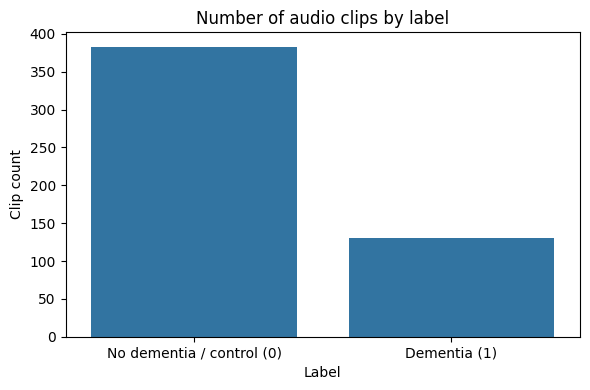

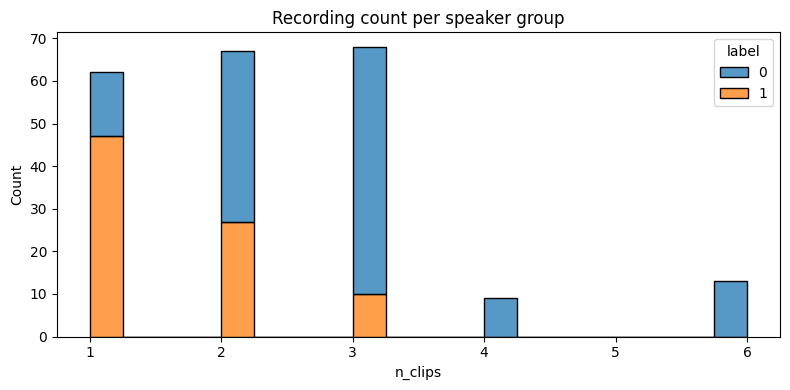

Other metadata columns: ['class_folder', 'file_id', 'metadata_file', 'metadata_label', 'metadata_path', 'metadata_match']

class_folder value counts:


,count
class_folder,
nodementia,383
dementia,131



metadata_label value counts:


,count
metadata_label,
nodementia,208
NaN,180
dementia,126



metadata_match value counts:


,count
metadata_match,
True,334
False,180


In [ ]:
# Class distribution (clip level)
plt.figure(figsize=(6,4))
sns.countplot(data=data, x='label')
plt.xticks([0,1], ['No dementia / control (0)', 'Dementia (1)'])
plt.title('Number of audio clips by label')
plt.xlabel('Label'); plt.ylabel('Clip count'); plt.tight_layout(); plt.show()

# Number of recordings per speaker/person
speaker_counts = data.groupby(['speaker_id','label']).size().reset_index(name='n_clips')
plt.figure(figsize=(8,4))
sns.histplot(data=speaker_counts, x='n_clips', hue='label', bins=20, multiple='stack')
plt.title('Recording count per speaker group'); plt.tight_layout(); plt.show()

# Inspect any numeric/categorical metadata columns available beyond audio path / label.
excluded = {'audio_path','label','speaker_id','source_split'}
extra_cols = [c for c in data.columns if c not in excluded]
print('Other metadata columns:', extra_cols)
for col in extra_cols:
    if data[col].nunique(dropna=True) <= 20:
        print(f'\n{col} value counts:')
        display(data[col].value_counts(dropna=False).head(20).to_frame('count'))

In [ ]:
# Audit speaker groups before train/test splitting

speaker_audit = (
    data.groupby("speaker_id")
    .agg(
        recordings=("audio_path", "count"),
        unique_labels=("label", "nunique"),
        label_values=("label", lambda s: sorted(s.unique()))
    )
    .sort_values("recordings", ascending=False)
)

print("Total speaker groups:", len(speaker_audit))
print("Speakers with multiple labels:",
      int((speaker_audit["unique_labels"] > 1).sum()))

print("\nLargest speaker groups:")
display(speaker_audit.head(20))

print("\nSpeakers with conflicting labels:")
display(speaker_audit[speaker_audit["unique_labels"] > 1])

Total speaker groups: 219
Speakers with multiple labels: 0

Largest speaker groups:


,recordings,unique_labels,label_values
speaker_id,,,
anthonyhopkins,6,1,[0]
angela_lansbury,6,1,[0]
betty_white,6,1,[0]
billwyman,6,1,[0]
bobdole,6,1,[0]
harrybelafonte,6,1,[0]
donaldsutherland,6,1,[0]
christopher_plummer,6,1,[0]
clint_eastwood,6,1,[0]



Speakers with conflicting labels:


,recordings,unique_labels,label_values
speaker_id,,,


Auditing audio:   0%|          | 0/514 [00:00<?, ?it/s]

Audio read failures: 0


duration_sec                                                  \
             count    mean     std  min     25%    50%   75%   max   
label                                                                
0            383.0  45.764  16.100  6.0  32.000  53.00  60.0  60.0   
1            131.0  44.825  16.962  8.5  33.006  49.01  60.0  60.0   

      rms_amplitude         ... near_silence_fraction        clipped_fraction  \
              count   mean  ...                   75%    max            count   
label                       ...                                                 
0             383.0  0.050  ...                 0.019  0.828            383.0   
1             131.0  0.056  ...                 0.017  0.128            131.0   

                                            
      mean  std  min  25%  50%  75%    max  
label                                       
0      0.0  0.0  0.0  0.0  0.0  0.0  0.001  
1      0.0  0.0  0.0  0.0  0.0  0.0  0.000  

[2 rows x 32 columns]

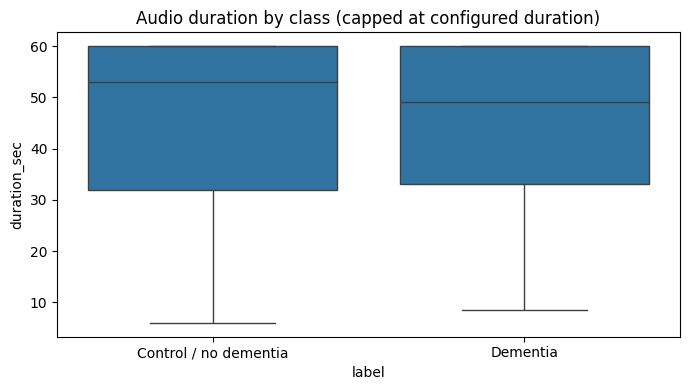

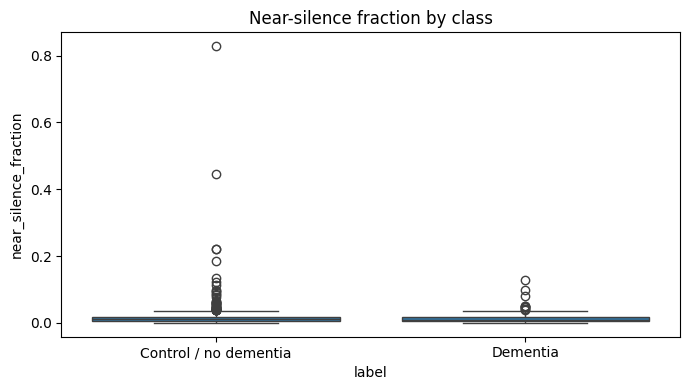

In [ ]:
import librosa
import librosa.display
import soundfile as sf

SR = 16000
MAX_AUDIO_SECONDS = 60  # cap compute per clip; increase or set None if justified and resources allow


def inspect_audio(path, max_seconds=MAX_AUDIO_SECONDS):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True, duration=max_seconds)
        if len(y) == 0:
            raise ValueError('empty audio')
        duration = len(y) / sr
        peak = float(np.max(np.abs(y)))
        rms = float(np.sqrt(np.mean(y**2)))
        silence_fraction = float(np.mean(np.abs(y) < 1e-4))
        clipped_fraction = float(np.mean(np.abs(y) >= 0.999))
        return {'duration_sec': duration, 'sample_rate': sr, 'peak_amplitude': peak,
                'rms_amplitude': rms, 'near_silence_fraction': silence_fraction,
                'clipped_fraction': clipped_fraction, 'audio_ok': True, 'audio_error': ''}
    except Exception as e:
        return {'duration_sec': np.nan, 'sample_rate': np.nan, 'peak_amplitude': np.nan,
                'rms_amplitude': np.nan, 'near_silence_fraction': np.nan,
                'clipped_fraction': np.nan, 'audio_ok': False, 'audio_error': str(e)[:200]}

quality_rows = []
for path in tqdm(data['audio_path'], desc='Auditing audio'):
    quality_rows.append(inspect_audio(path))
quality = pd.DataFrame(quality_rows)
data = pd.concat([data.reset_index(drop=True), quality], axis=1)
print('Audio read failures:', int((~data['audio_ok']).sum()))
if (~data['audio_ok']).any():
    display(data.loc[~data['audio_ok'], ['audio_path','audio_error']].head(20))

data = data[data['audio_ok']].reset_index(drop=True)
if data['label'].nunique() < 2:
    raise ValueError('Audio filtering removed a class. Inspect the failed audio rows.')

display(data.groupby('label')[['duration_sec','rms_amplitude','near_silence_fraction','clipped_fraction']].describe().round(3))
plt.figure(figsize=(7,4))
sns.boxplot(data=data, x='label', y='duration_sec')
plt.xticks([0,1], ['Control / no dementia','Dementia'])
plt.title('Audio duration by class (capped at configured duration)')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,4))
sns.boxplot(data=data, x='label', y='near_silence_fraction')
plt.xticks([0,1], ['Control / no dementia','Dementia'])
plt.title('Near-silence fraction by class')
plt.tight_layout(); plt.show()

Label: 0 | speaker_id: harrybelafonte | file: HarryBelafonte_3.wav


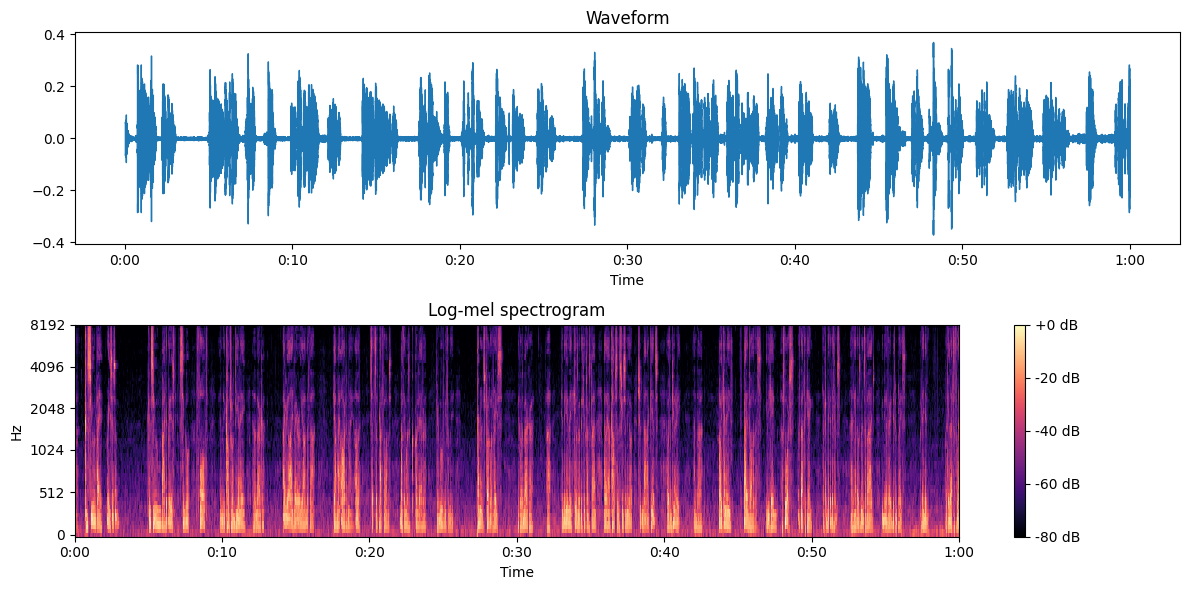

In [ ]:
# Listen to one sample and visualize waveform + log-mel spectrogram.
from IPython.display import Audio, display as ipy_display
sample_row = data.sample(1, random_state=SEED).iloc[0]
y, sr = librosa.load(sample_row['audio_path'], sr=SR, mono=True, duration=MAX_AUDIO_SECONDS)
print('Label:', int(sample_row['label']), '| speaker_id:', sample_row['speaker_id'], '| file:', Path(sample_row['audio_path']).name)
ipy_display(Audio(y, rate=sr))

fig, axes = plt.subplots(2, 1, figsize=(12,6))
librosa.display.waveshow(y, sr=sr, ax=axes[0])
axes[0].set_title('Waveform')
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64, n_fft=400, hop_length=160)
S_db = librosa.power_to_db(S, ref=np.max)
img = librosa.display.specshow(S_db, sr=sr, hop_length=160, x_axis='time', y_axis='mel', ax=axes[1])
axes[1].set_title('Log-mel spectrogram')
fig.colorbar(img, ax=axes[1], format='%+2.0f dB')
plt.tight_layout(); plt.show()

## 6. Audio preprocessing and feature engineering

For a robust first baseline, transform each clip to mono 16 kHz and extract summary features from the waveform. MFCCs summarize the speech spectrum; spectral centroid/bandwidth/rolloff describe spectral shape; RMS/ZCR describe signal energy and crossings; chroma is included as an exploratory feature. These are **not dementia-specific features**.

We aggregate mean and standard deviation over frames so clips of different lengths become fixed-length rows. Normalization is fitted inside each ML pipeline on the training split only.

In [ ]:
def safe_mean_std(arr, prefix, out):
    arr = np.asarray(arr)
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)
    for i, row in enumerate(arr):
        out[f'{prefix}_{i+1}_mean'] = float(np.nanmean(row))
        out[f'{prefix}_{i+1}_std'] = float(np.nanstd(row))


def extract_features(path):
    y, sr = librosa.load(path, sr=SR, mono=True, duration=MAX_AUDIO_SECONDS)
    if y.size < int(0.25 * sr):
        raise ValueError('Audio is shorter than 0.25 seconds')
    y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)
    out = {
        'duration_sec': float(len(y) / sr),
        'rms_global': float(np.sqrt(np.mean(y**2))),
        'peak_amplitude': float(np.max(np.abs(y))),
        'near_silence_fraction': float(np.mean(np.abs(y) < 1e-4)),
        'zero_crossing_rate_mean': float(np.mean(librosa.feature.zero_crossing_rate(y=y))),
        'zero_crossing_rate_std': float(np.std(librosa.feature.zero_crossing_rate(y=y))),
    }
    for feature_name, func in [
        ('spectral_centroid', librosa.feature.spectral_centroid),
        ('spectral_bandwidth', librosa.feature.spectral_bandwidth),
        ('spectral_rolloff', librosa.feature.spectral_rolloff),
    ]:
        arr = func(y=y, sr=sr)
        out[f'{feature_name}_mean'] = float(np.mean(arr))
        out[f'{feature_name}_std'] = float(np.std(arr))
    rms_frame = librosa.feature.rms(y=y)
    out['rms_frame_mean'] = float(np.mean(rms_frame))
    out['rms_frame_std'] = float(np.std(rms_frame))

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    safe_mean_std(mfcc, 'mfcc', out)
    delta = librosa.feature.delta(mfcc, order=1)
    safe_mean_std(delta, 'mfcc_delta', out)
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    safe_mean_std(chroma, 'chroma', out)
    return out

FEATURE_CACHE = OUTPUT_DIR / 'audio_features.csv'
USE_FEATURE_CACHE = True

if USE_FEATURE_CACHE and FEATURE_CACHE.exists():
    cached = pd.read_csv(FEATURE_CACHE)
    # Reuse the cache only if its audio paths exactly match current valid rows.
    if set(cached['audio_path'].astype(str)) == set(data['audio_path'].astype(str)):
        feature_df = cached
        print('Loaded cached feature matrix:', feature_df.shape)
    else:
        feature_df = None
else:
    feature_df = None

if feature_df is None:
    feature_rows = []
    feature_errors = []
    for row in tqdm(data.itertuples(index=False), total=len(data), desc='Extracting audio features'):
        path = getattr(row, 'audio_path')
        try:
            f = {f'feat_{k}': v for k, v in extract_features(path).items()}
            f['audio_path'] = path
            feature_rows.append(f)
        except Exception as e:
            feature_errors.append({'audio_path': path, 'error': str(e)[:250]})
    features_only = pd.DataFrame(feature_rows)
    if feature_errors:
        print('Feature extraction failures:', len(feature_errors))
        display(pd.DataFrame(feature_errors).head(20))
    feature_df = data.merge(features_only, on='audio_path', how='inner', suffixes=('', '_feature'))
    feature_df.to_csv(FEATURE_CACHE, index=False)
    print('Saved feature cache:', FEATURE_CACHE)

# Refresh labels and speaker IDs from the current verified data table

lookup = (
    data[["audio_path", "label", "speaker_id"]]
    .drop_duplicates("audio_path")
    .copy()
)

lookup["audio_path"] = lookup["audio_path"].astype(str)
feature_df["audio_path"] = feature_df["audio_path"].astype(str)

lookup = lookup.set_index("audio_path")

feature_df["label"] = feature_df["audio_path"].map(lookup["label"])
feature_df["speaker_id"] = feature_df["audio_path"].map(
    lookup["speaker_id"]
)

assert feature_df["speaker_id"].notna().all(), (
    "Some feature rows could not be matched to current speaker IDs."
)

assert feature_df["label"].notna().all(), (
    "Some feature rows could not be matched to current labels."
)

# Save the corrected cache
feature_df.to_csv(FEATURE_CACHE, index=False)

print("Updated cached labels and speaker IDs.")
print("Feature rows:", len(feature_df))
print("Unique speakers:", feature_df["speaker_id"].nunique())
print('Feature table shape:', feature_df.shape)
display(feature_df.head())

Loaded cached feature matrix: (514, 108)
Updated cached labels and speaker IDs.
Feature rows: 514
Unique speakers: 219
Feature table shape: (514, 108)


,audio_path,label,class_folder,file_id,metadata_file,metadata_label,metadata_path,source_split,metadata_match,speaker_id,...,feat_chroma_8_mean,feat_chroma_8_std,feat_chroma_9_mean,feat_chroma_9_std,feat_chroma_10_mean,feat_chroma_10_std,feat_chroma_11_mean,feat_chroma_11_std,feat_chroma_12_mean,feat_chroma_12_std
0,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,AbeBurrows_5,AbeBurrows_5,dementia,/content/drive/My Drive/type3/data/dementia/Ab...,train,True,abeburrows,...,0.373850,0.303141,0.360007,0.300349,0.374868,0.321566,0.411838,0.337012,0.397741,0.326222
1,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_0,aileenhernandez_0,dementia,/content/drive/My Drive/type3/data/dementia/Ai...,train,True,aileenhernandez,...,0.322613,0.310526,0.348285,0.317536,0.401964,0.339733,0.394299,0.336505,0.361024,0.329849
2,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_5_1,aileenhernandez_5_1,dementia,/content/drive/My Drive/type3/data/dementia/Ai...,train,True,aileenhernandez,...,0.381937,0.328615,0.340398,0.307776,0.325656,0.295695,0.337812,0.299812,0.335643,0.298292
3,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,aileenhernandez_5_2,aileenhernandez_5_2,dementia,/content/drive/My Drive/type3/data/dementia/Ai...,train,True,aileenhernandez,...,0.410292,0.327227,0.402613,0.334647,0.370983,0.322166,0.371251,0.309527,0.362492,0.307499
4,/content/drive/MyDrive/DementiaVoiceAI/data/au...,1,dementia,alanramsey_10,alanramsey_10,dementia,/content/drive/My Drive/type3/data/dementia/Al...,train,True,alanramsey,...,0.461211,0.304198,0.486358,0.320930,0.497484,0.315830,0.436522,0.291105,0.417505,0.283532


## 7. Feature-level EDA and data-quality checks

Feature count: 97 | rows: 514
Top missing features:


,missing_fraction
audio_error,1.0
duration_sec,0.0
sample_rate,0.0
rms_amplitude,0.0
peak_amplitude,0.0
near_silence_fraction,0.0
clipped_fraction,0.0
feat_duration_sec,0.0
feat_rms_global,0.0
feat_peak_amplitude,0.0


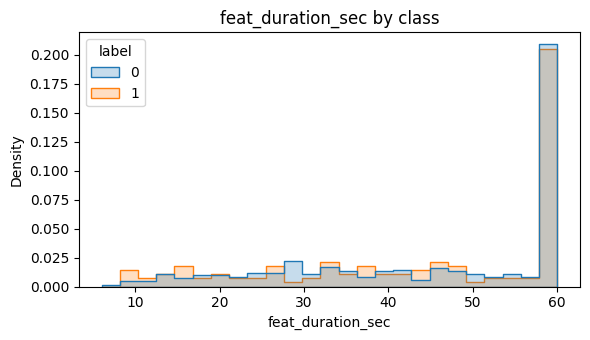

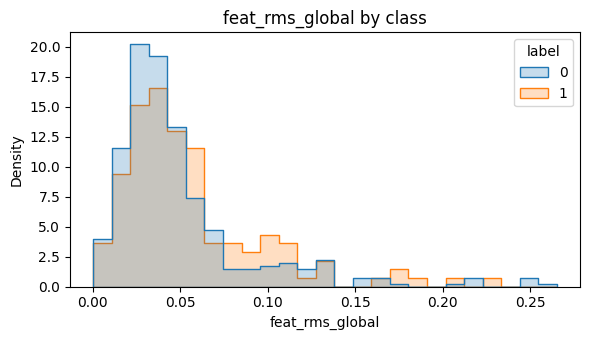

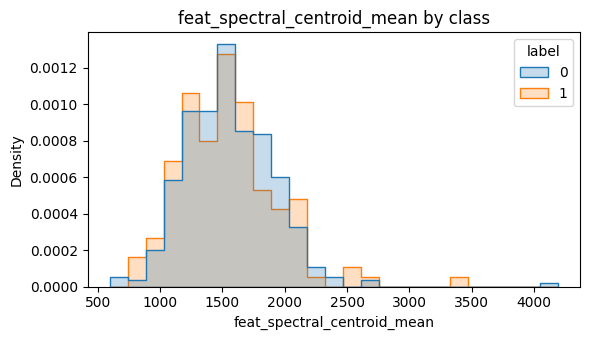

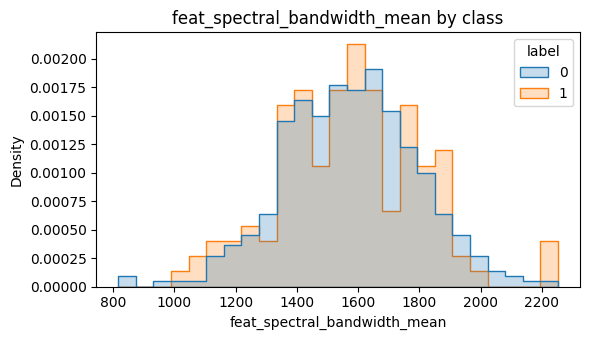

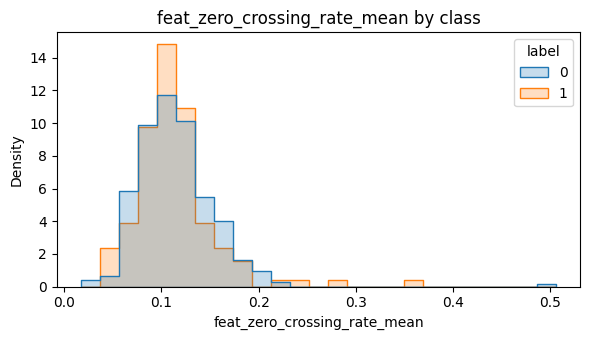

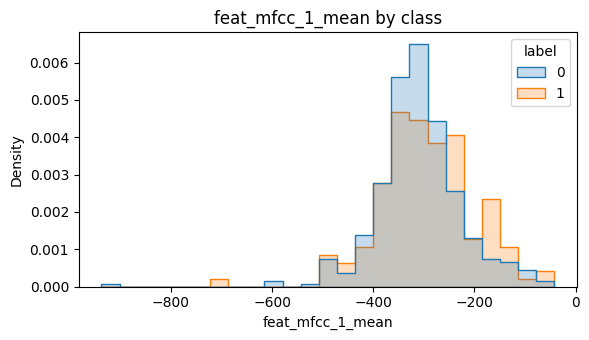

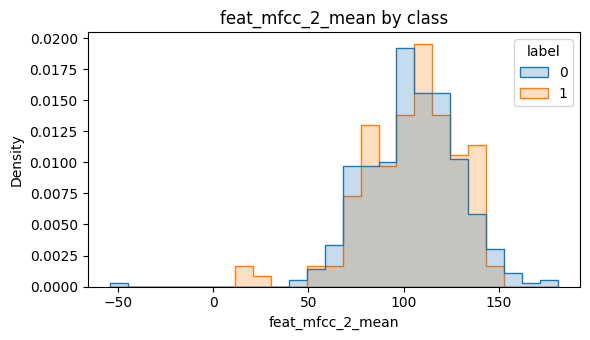

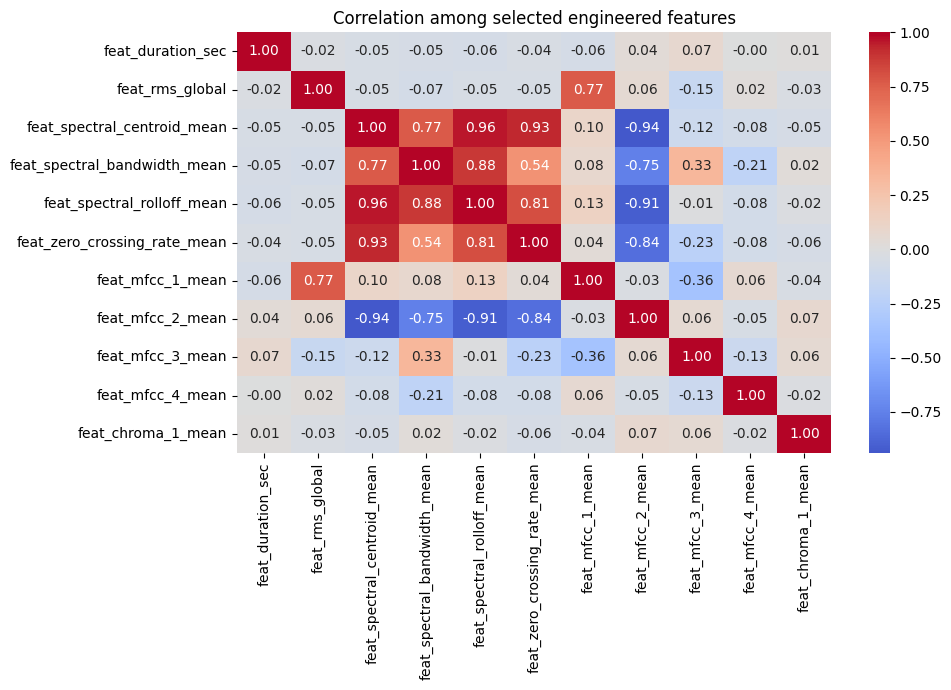

In [ ]:
metadata_cols = {'audio_path','source_split','speaker_id','label','audio_ok','audio_error'}
non_feature_cols = metadata_cols | {'duration_sec','sample_rate','peak_amplitude','rms_amplitude','near_silence_fraction','clipped_fraction'}
feature_cols = [c for c in feature_df.select_dtypes(include=np.number).columns if c not in {'label'}]

missing_pct = feature_df[feature_cols].isna().mean().sort_values(ascending=False)
print('Feature count:', len(feature_cols), '| rows:', len(feature_df))
print('Top missing features:')
display(missing_pct.head(15).to_frame('missing_fraction'))

# Class-wise feature distributions for selected signal summaries.
plot_cols = [c for c in ['feat_duration_sec','feat_rms_global','feat_spectral_centroid_mean','feat_spectral_bandwidth_mean','feat_zero_crossing_rate_mean','feat_mfcc_1_mean','feat_mfcc_2_mean'] if c in feature_df.columns]
for col in plot_cols:
    plt.figure(figsize=(6,3.5))
    sns.histplot(data=feature_df, x=col, hue='label', bins=25, stat='density', common_norm=False, element='step')
    plt.title(f'{col} by class')
    plt.tight_layout(); plt.show()

# Correlation heatmap of a modest subset to avoid an unreadable plot.
cor_cols = [c for c in ['feat_duration_sec','feat_rms_global','feat_spectral_centroid_mean','feat_spectral_bandwidth_mean','feat_spectral_rolloff_mean','feat_zero_crossing_rate_mean','feat_mfcc_1_mean','feat_mfcc_2_mean','feat_mfcc_3_mean','feat_mfcc_4_mean','feat_chroma_1_mean'] if c in feature_df.columns]
if len(cor_cols) > 1:
    plt.figure(figsize=(10,7))
    sns.heatmap(feature_df[cor_cols].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
    plt.title('Correlation among selected engineered features')
    plt.tight_layout(); plt.show()

## 8. Leakage-safe train / validation / test split

We use `StratifiedGroupKFold` and keep every `speaker_id` in a single partition: approximately 60% train, 20% validation, 20% test. The validation set is used for model selection. The test set is reserved for final evaluation.

If there are too few unique speakers, or if the automatically inferred speaker IDs are not trustworthy, stop and correct the metadata before continuing.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Keep only rows that have labels, group IDs, and extracted features.
model_df = feature_df.dropna(subset=['label','speaker_id']).copy()
model_df['label'] = model_df['label'].astype(int)
feature_cols = [c for c in model_df.select_dtypes(include=np.number).columns if c.startswith('feat_')]
# Only audio-derived engineered features are used. Demographics/source metadata is excluded to reduce confounding/leakage.

X = model_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = model_df['label'].to_numpy()
groups = model_df['speaker_id'].astype(str).to_numpy()
unique_groups = np.unique(groups)
print('Rows:', len(model_df), '| Features:', len(feature_cols), '| Unique speakers:', len(unique_groups))
print('Overall labels:', pd.Series(y).value_counts().sort_index().to_dict())

if len(unique_groups) < 5:
    raise ValueError('Need at least 5 distinct speaker groups for this grouped split. Fix speaker IDs / obtain more subjects.')

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_id = np.full(len(model_df), -1, dtype=int)
for fold, (_, heldout_idx) in enumerate(sgkf.split(X, y, groups)):
    fold_id[heldout_idx] = fold

# Fold 0 = test; Fold 4 = validation; Folds 1-3 = training.
train_idx = np.where(np.isin(fold_id, [1,2,3]))[0]
val_idx = np.where(fold_id == 4)[0]
test_idx = np.where(fold_id == 0)[0]
X_train, y_train, g_train = X.iloc[train_idx], y[train_idx], groups[train_idx]
X_val, y_val, g_val = X.iloc[val_idx], y[val_idx], groups[val_idx]
X_test, y_test, g_test = X.iloc[test_idx], y[test_idx], groups[test_idx]

for split_name, idx, ys, gs in [('train',train_idx,y_train,g_train),('validation',val_idx,y_val,g_val),('test',test_idx,y_test,g_test)]:
    print(f'{split_name:10s}: rows={len(idx):4d}, speakers={len(np.unique(gs)):3d}, label counts={pd.Series(ys).value_counts().sort_index().to_dict()}')

# Hard check: no subject overlap across splits.
assert set(g_train).isdisjoint(set(g_val))
assert set(g_train).isdisjoint(set(g_test))
assert set(g_val).isdisjoint(set(g_test))
assert len(np.unique(y_train)) == 2 and len(np.unique(y_val)) == 2 and len(np.unique(y_test)) == 2, 'A split is missing a class; use more subjects or revise the grouped split strategy.'
print('Speaker leakage check passed: no group overlaps.')

Rows: 514 | Features: 90 | Unique speakers: 219
Overall labels: {0: 383, 1: 131}
train     : rows= 318, speakers=132, label counts={0: 240, 1: 78}
validation: rows=  95, speakers= 43, label counts={0: 66, 1: 29}
test      : rows= 101, speakers= 44, label counts={0: 77, 1: 24}
Speaker leakage check passed: no group overlaps.


In [ ]:

# THRESHOLD ANALYSIS — VALIDATION DATA ONLY
# Uses the fitted models and validation probabilities already in memory.

import numpy as np
import pandas as pd

threshold_rows = []

for model_name, probabilities in val_probabilities.items():
    for threshold in np.arange(0.05, 0.96, 0.05):
        metrics = evaluate_probabilities(
            y_val,
            probabilities,
            threshold=float(threshold)
        )

        threshold_rows.append({
            "model": model_name,
            "threshold": round(float(threshold), 2),
            "balanced_accuracy": metrics["balanced_accuracy"],
            "dementia_recall": metrics["sensitivity_recall_dementia"],
            "specificity": metrics["specificity"],
            "precision": metrics["precision_dementia"],
            "f1_dementia": metrics["f1_dementia"],
            "roc_auc": metrics["roc_auc"]
        })

threshold_results = pd.DataFrame(threshold_rows)

print("Best validation threshold for each model:")
best_thresholds = (
    threshold_results
    .sort_values(
        ["model", "balanced_accuracy", "dementia_recall"],
        ascending=[True, False, False]
    )
    .groupby("model")
    .head(1)
    .sort_values("balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)

display(best_thresholds.round(3))

print("\nThresholds with dementia recall >= 70% on validation:")
high_recall = threshold_results[
    threshold_results["dementia_recall"] >= 0.70
].sort_values(
    ["specificity", "balanced_accuracy"],
    ascending=False
)

if high_recall.empty:
    print(
        "No tested threshold reached 70% dementia recall. "
        "This suggests that threshold adjustment alone may not be enough."
    )
else:
    display(high_recall.head(15).round(3))


Best validation threshold for each model:


,model,threshold,balanced_accuracy,dementia_recall,specificity,precision,f1_dementia,roc_auc
0,Random Forest,0.35,0.583,0.241,0.924,0.583,0.341,0.498
1,Logistic Regression,0.20,0.562,0.655,0.470,0.352,0.458,0.515
2,RBF SVM,0.20,0.547,0.655,0.439,0.339,0.447,0.499
3,Hist Gradient Boosting,0.05,0.525,0.655,0.394,0.322,0.432,0.476
4,XGBoost,0.55,0.517,0.034,1.000,1.000,0.067,0.493
5,Extra Trees,0.40,0.504,0.069,0.939,0.333,0.114,0.471



Thresholds with dementia recall >= 70% on validation:


,model,threshold,balanced_accuracy,dementia_recall,specificity,precision,f1_dementia,roc_auc
96,XGBoost,0.10,0.506,0.724,0.288,0.309,0.433,0.493
1,Logistic Regression,0.10,0.493,0.759,0.227,0.301,0.431,0.515
41,Random Forest,0.20,0.487,0.793,0.182,0.299,0.434,0.498
61,Extra Trees,0.25,0.487,0.793,0.182,0.299,0.434,0.471
21,RBF SVM,0.15,0.516,0.897,0.136,0.313,0.464,0.499
0,Logistic Regression,0.05,0.492,0.862,0.121,0.301,0.446,0.515
95,XGBoost,0.05,0.503,0.931,0.076,0.307,0.462,0.493
40,Random Forest,0.15,0.508,1.000,0.015,0.309,0.472,0.498
20,RBF SVM,0.10,0.490,0.966,0.015,0.301,0.459,0.499
60,Extra Trees,0.20,0.473,0.931,0.015,0.293,0.446,0.471


In [ ]:

# ============================================================
# GROUPED CROSS-VALIDATION ON THE TRAINING PARTITION
# Prevents the same inferred speaker appearing in train and fold.
# Does not use the validation or test partitions.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer, recall_score

# Five-fold stratified group CV
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "dementia_recall": make_scorer(
        recall_score,
        pos_label=1,
        zero_division=0
    )
}

cv_results = []

# Majority-class baseline for comparison
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyClassifier(strategy="most_frequent"))
])

models_to_evaluate = {
    "Majority baseline": baseline,
    **models
}

for name, estimator in models_to_evaluate.items():
    print(f"Evaluating: {name}")

    result = cross_validate(
        estimator,
        X_train,
        y_train,
        groups=g_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    row = {"model": name}

    for metric in scoring:
        values = result[f"test_{metric}"]
        row[f"{metric}_mean"] = np.mean(values)
        row[f"{metric}_std"] = np.std(values, ddof=1)

    cv_results.append(row)

cv_table = pd.DataFrame(cv_results)

# Sort by mean balanced accuracy, not ordinary accuracy
cv_table = cv_table.sort_values(
    "balanced_accuracy_mean",
    ascending=False
).reset_index(drop=True)

display(cv_table.round(3))

print(
    "\nInterpretation: compare mean balanced accuracy and ROC-AUC "
    "against the majority baseline. Large standard deviations "
    "indicate unstable performance across speaker groups."
)


Evaluating: Majority baseline
Evaluating: Logistic Regression
Evaluating: RBF SVM
Evaluating: Random Forest
Evaluating: Extra Trees
Evaluating: Hist Gradient Boosting
Evaluating: XGBoost


,model,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,dementia_recall_mean,dementia_recall_std
0,Logistic Regression,0.568,0.100,0.569,0.140,0.362,0.129,0.446,0.183
1,Hist Gradient Boosting,0.523,0.072,0.536,0.100,0.284,0.061,0.152,0.160
2,RBF SVM,0.511,0.092,0.580,0.125,0.346,0.117,0.290,0.182
3,Majority baseline,0.500,0.000,0.500,0.000,0.248,0.051,0.000,0.000
4,Random Forest,0.486,0.032,0.574,0.124,0.331,0.067,0.000,0.000
5,XGBoost,0.486,0.004,0.539,0.129,0.298,0.058,0.052,0.050
6,Extra Trees,0.485,0.027,0.571,0.088,0.307,0.055,0.017,0.037



Interpretation: compare mean balanced accuracy and ROC-AUC against the majority baseline. Large standard deviations indicate unstable performance across speaker groups.


In [ ]:

# ============================================================
# EXPERIMENT: ONE FEATURE ROW PER SPEAKER
# Uses median audio features per person.
# Preserves the existing train/validation/test speaker split.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone

# 1. Prepare the extracted feature table
speaker_source = feature_df.dropna(
    subset=["speaker_id", "label"]
).copy()

speaker_source["speaker_id"] = (
    speaker_source["speaker_id"].astype(str)
)
speaker_source["label"] = speaker_source["label"].astype(int)

speaker_feature_cols = [
    c for c in speaker_source.columns
    if c.startswith("feat_")
    and pd.api.types.is_numeric_dtype(speaker_source[c])
]

if not speaker_feature_cols:
    raise ValueError("No numeric feat_ columns found in feature_df.")

# 2. Verify that each inferred speaker has only one label
label_counts = (
    speaker_source.groupby("speaker_id")["label"].nunique()
)

conflicts = label_counts[label_counts > 1]

if not conflicts.empty:
    raise ValueError(
        "Some speaker IDs have conflicting labels. "
        "Investigate them before aggregation."
    )

# 3. Aggregate each speaker's recordings using median features
aggregation = {
    "label": ("label", "first"),
    "n_recordings": ("label", "size"),
}

aggregation.update({
    col: (col, "median")
    for col in speaker_feature_cols
})

speaker_df = (
    speaker_source
    .groupby("speaker_id")
    .agg(**aggregation)
    .reset_index()
)

# 4. Preserve the existing split assignments
split_map = {}

for split_name, group_ids in [
    ("train", g_train),
    ("validation", g_val),
    ("test", g_test),
]:
    for group_id in group_ids:
        split_map[str(group_id)] = split_name

speaker_df["split"] = speaker_df["speaker_id"].map(split_map)

unassigned = speaker_df["split"].isna().sum()

print("Speakers with no existing split:", unassigned)

if unassigned:
    raise ValueError(
        "Some speaker IDs could not be matched to the existing splits."
    )

# 5. Display the new dataset
print("\nSpeaker-level dataset:", speaker_df.shape)
print("Audio features:", len(speaker_feature_cols))
print("Recordings per speaker:")
display(speaker_df["n_recordings"].describe().to_frame())

print("\nSpeaker counts and class distributions:")
display(
    speaker_df.groupby("split")["label"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "speakers",
        "sum": "dementia_speakers",
        "mean": "dementia_fraction",
    })
)

# 6. Prepare train, validation and test matrices
train_sp = speaker_df[speaker_df["split"] == "train"]
val_sp = speaker_df[speaker_df["split"] == "validation"]
test_sp = speaker_df[speaker_df["split"] == "test"]

for split_name, part in [
    ("train", train_sp),
    ("validation", val_sp),
    ("test", test_sp),
]:
    if part["label"].nunique() != 2:
        raise ValueError(
            f"{split_name} does not contain both classes."
        )

X_train_sp = train_sp[speaker_feature_cols].replace(
    [np.inf, -np.inf], np.nan
)
y_train_sp = train_sp["label"].to_numpy()

X_val_sp = val_sp[speaker_feature_cols].replace(
    [np.inf, -np.inf], np.nan
)
y_val_sp = val_sp["label"].to_numpy()

X_test_sp = test_sp[speaker_feature_cols].replace(
    [np.inf, -np.inf], np.nan
)
y_test_sp = test_sp["label"].to_numpy()

# 7. Fit models and select using validation balanced accuracy only
speaker_models = {}
speaker_val_rows = []

for name, template in models.items():
    print("Training speaker-level model:", name)

    estimator = clone(template)
    estimator.fit(X_train_sp, y_train_sp)

    val_prob = estimator.predict_proba(X_val_sp)[:, 1]

    metrics = evaluate_probabilities(
        y_val_sp,
        val_prob,
        threshold=0.5
    )

    metrics["model"] = name
    speaker_val_rows.append(metrics)
    speaker_models[name] = estimator

speaker_val_results = (
    pd.DataFrame(speaker_val_rows)
    .sort_values(
        ["balanced_accuracy", "roc_auc"],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nValidation results — speaker-level experiment:")
display(speaker_val_results.round(3))

# 8. Choose the model without looking at test results
selected_name = speaker_val_results.iloc[0]["model"]
selected_model = speaker_models[selected_name]

print("\nSelected using validation only:", selected_name)

# Evaluate the selected model once on held-out speakers
test_prob_sp = selected_model.predict_proba(X_test_sp)[:, 1]

speaker_test_metrics = evaluate_probabilities(
    y_test_sp,
    test_prob_sp,
    threshold=0.5
)

print("\nHeld-out speaker test results:")
display(pd.DataFrame([speaker_test_metrics]).round(3))


Speakers with no existing split: 0

Speaker-level dataset: (219, 94)
Audio features: 90
Recordings per speaker:


,n_recordings
count,219.000000
mean,2.347032
std,1.262780
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,6.000000



Speaker counts and class distributions:


,speakers,dementia_speakers,dementia_fraction
split,,,
test,44,16,0.363636
train,132,47,0.356061
validation,43,21,0.488372


Training speaker-level model: Logistic Regression
Training speaker-level model: RBF SVM
Training speaker-level model: Random Forest
Training speaker-level model: Extra Trees
Training speaker-level model: Hist Gradient Boosting
Training speaker-level model: XGBoost

Validation results — speaker-level experiment:


,accuracy,balanced_accuracy,precision_dementia,sensitivity_recall_dementia,specificity,f1_dementia,roc_auc,pr_auc,tn,fp,fn,tp,model
0,0.651,0.645,0.800,0.381,0.909,0.516,0.686,0.718,20,2,13,8,RBF SVM
1,0.581,0.578,0.600,0.429,0.727,0.500,0.558,0.617,16,6,12,9,Logistic Regression
2,0.535,0.526,0.600,0.143,0.909,0.231,0.628,0.597,20,2,18,3,Hist Gradient Boosting
3,0.535,0.525,0.667,0.095,0.955,0.167,0.671,0.636,21,1,19,2,Random Forest
4,0.512,0.502,0.500,0.095,0.909,0.160,0.682,0.645,20,2,19,2,Extra Trees
5,0.488,0.478,0.333,0.048,0.909,0.083,0.587,0.556,20,2,20,1,XGBoost



Selected using validation only: RBF SVM

Held-out speaker test results:


,accuracy,balanced_accuracy,precision_dementia,sensitivity_recall_dementia,specificity,f1_dementia,roc_auc,pr_auc,tn,fp,fn,tp
0,0.705,0.647,0.636,0.438,0.857,0.519,0.768,0.692,24,4,9,7


In [ ]:

# ============================================================
# SPEAKER-LEVEL THRESHOLD ANALYSIS
# Threshold selection uses validation data only.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# Get dementia probabilities for validation speakers
class_order = list(selected_model.classes_)
positive_index = class_order.index(1)

val_prob_sp = selected_model.predict_proba(X_val_sp)[:, positive_index]

threshold_rows = []

for threshold in np.arange(0.05, 0.96, 0.01):
    pred = (val_prob_sp >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_sp, pred, labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "balanced_accuracy": balanced_accuracy_score(
            y_val_sp, pred
        ),
        "dementia_recall": recall_score(
            y_val_sp, pred, zero_division=0
        ),
        "specificity": tn / (tn + fp) if tn + fp else 0,
        "precision": precision_score(
            y_val_sp, pred, zero_division=0
        ),
        "f1_dementia": f1_score(
            y_val_sp, pred, zero_division=0
        ),
        "TP": tp,
        "FN": fn,
        "TN": tn,
        "FP": fp
    })

threshold_df = pd.DataFrame(threshold_rows)

print("Top 10 thresholds by validation balanced accuracy:")
display(
    threshold_df.sort_values(
        ["balanced_accuracy", "dementia_recall"],
        ascending=False
    ).head(10).round(3)
)

print("\nThresholds with at least 60% dementia recall:")
high_recall_df = threshold_df[
    threshold_df["dementia_recall"] >= 0.60
].sort_values(
    ["balanced_accuracy", "specificity"],
    ascending=False
)

if high_recall_df.empty:
    print("No tested threshold achieved 60% validation recall.")
else:
    display(high_recall_df.head(10).round(3))


Top 10 thresholds by validation balanced accuracy:


,threshold,balanced_accuracy,dementia_recall,specificity,precision,f1_dementia,TP,FN,TN,FP
39,0.44,0.693,0.476,0.909,0.833,0.606,10,11,20,2
40,0.45,0.693,0.476,0.909,0.833,0.606,10,11,20,2
38,0.43,0.670,0.476,0.864,0.769,0.588,10,11,19,3
23,0.28,0.652,0.667,0.636,0.636,0.651,14,7,14,8
24,0.29,0.652,0.667,0.636,0.636,0.651,14,7,14,8
41,0.46,0.645,0.381,0.909,0.800,0.516,8,13,20,2
42,0.47,0.645,0.381,0.909,0.800,0.516,8,13,20,2
43,0.48,0.645,0.381,0.909,0.800,0.516,8,13,20,2
44,0.49,0.645,0.381,0.909,0.800,0.516,8,13,20,2
21,0.26,0.631,0.762,0.500,0.593,0.667,16,5,11,11



Thresholds with at least 60% dementia recall:


,threshold,balanced_accuracy,dementia_recall,specificity,precision,f1_dementia,TP,FN,TN,FP
23,0.28,0.652,0.667,0.636,0.636,0.651,14,7,14,8
24,0.29,0.652,0.667,0.636,0.636,0.651,14,7,14,8
21,0.26,0.631,0.762,0.500,0.593,0.667,16,5,11,11
15,0.20,0.613,0.952,0.273,0.556,0.702,20,1,6,16
16,0.21,0.613,0.952,0.273,0.556,0.702,20,1,6,16
17,0.22,0.613,0.952,0.273,0.556,0.702,20,1,6,16
22,0.27,0.606,0.667,0.545,0.583,0.622,14,7,12,10
10,0.15,0.591,1.000,0.182,0.538,0.700,21,0,4,18
14,0.19,0.590,0.952,0.227,0.541,0.690,20,1,5,17
18,0.23,0.589,0.905,0.273,0.543,0.679,19,2,6,16


In [ ]:

# ============================================================
# FINAL THRESHOLD EVALUATION — HELD-OUT SPEAKERS
# Threshold selected from validation balanced accuracy.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Preselected from validation results; do not tune on test labels.
FINAL_THRESHOLD = 0.44

positive_index = list(selected_model.classes_).index(1)

test_prob_sp = selected_model.predict_proba(X_test_sp)[:, positive_index]
test_pred_sp = (test_prob_sp >= FINAL_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test_sp,
    test_pred_sp,
    labels=[0, 1]
).ravel()

final_metrics = {
    "threshold": FINAL_THRESHOLD,
    "accuracy": accuracy_score(y_test_sp, test_pred_sp),
    "balanced_accuracy": balanced_accuracy_score(y_test_sp, test_pred_sp),
    "dementia_precision": precision_score(
        y_test_sp, test_pred_sp, pos_label=1, zero_division=0
    ),
    "dementia_recall": recall_score(
        y_test_sp, test_pred_sp, pos_label=1, zero_division=0
    ),
    "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
    "dementia_f1": f1_score(
        y_test_sp, test_pred_sp, pos_label=1, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test_sp, test_prob_sp),
    "average_precision": average_precision_score(
        y_test_sp, test_prob_sp
    )
}

print("Selected model:", selected_name)
print("Threshold selected on validation:", FINAL_THRESHOLD)

print("\nHeld-out test metrics:")
display(pd.DataFrame([final_metrics]).round(3))

print("\nConfusion matrix:")
print("                 Predicted control  Predicted dementia")
print(f"Actual control       {tn:>5}              {fp:>5}")
print(f"Actual dementia      {fn:>5}              {tp:>5}")

print("\nClassification report:")
print(classification_report(
    y_test_sp,
    test_pred_sp,
    labels=[0, 1],
    target_names=["Control", "Dementia"],
    zero_division=0
))


Selected model: RBF SVM
Threshold selected on validation: 0.44

Held-out test metrics:


,threshold,accuracy,balanced_accuracy,dementia_precision,dementia_recall,specificity,dementia_f1,roc_auc,average_precision
0,0.44,0.75,0.71,0.692,0.562,0.857,0.621,0.768,0.692



Confusion matrix:
                 Predicted control  Predicted dementia
Actual control          24                  4
Actual dementia          7                  9

Classification report:
              precision    recall  f1-score   support

     Control       0.77      0.86      0.81        28
    Dementia       0.69      0.56      0.62        16

    accuracy                           0.75        44
   macro avg       0.73      0.71      0.72        44
weighted avg       0.74      0.75      0.74        44



## 9. Train and compare classical ML models

Models are trained on engineered audio features. Missing values are imputed inside the pipeline; scaling is applied only where appropriate. We compare accuracy with **balanced accuracy, dementia recall/sensitivity, specificity, F1, ROC-AUC, and PR-AUC**. For a screening-style task, accuracy alone is not enough.


Training: Logistic Regression

Training: RBF SVM

Training: Random Forest

Training: Extra Trees

Training: Hist Gradient Boosting

Training: XGBoost


,accuracy,balanced_accuracy,precision_dementia,sensitivity_recall_dementia,specificity,f1_dementia,roc_auc,pr_auc,tn,fp,fn,tp,model
0,0.6947,0.5097,0.5000,0.0345,0.9848,0.0645,0.4927,0.3290,65,1,28,1,XGBoost
1,0.6947,0.5000,0.0000,0.0000,1.0000,0.0000,0.4979,0.3677,66,0,29,0,Random Forest
2,0.5579,0.4982,0.3030,0.3448,0.6515,0.3226,0.5152,0.3546,43,23,19,10,Logistic Regression
3,0.6842,0.4924,0.0000,0.0000,0.9848,0.0000,0.4995,0.3215,65,1,29,0,RBF SVM
4,0.6842,0.4924,0.0000,0.0000,0.9848,0.0000,0.4707,0.3115,65,1,29,0,Extra Trees
5,0.6421,0.4815,0.2222,0.0690,0.8939,0.1053,0.4765,0.2831,59,7,27,2,Hist Gradient Boosting


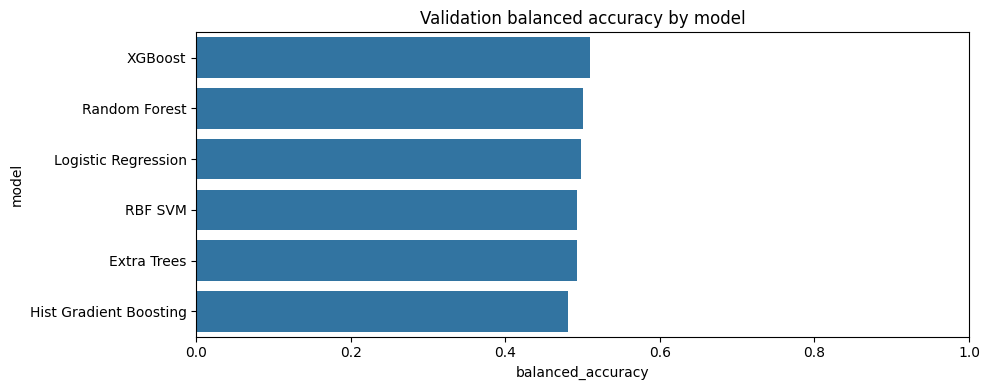

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

models = {
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED))
    ]),
    'RBF SVM': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', SVC(C=1.0, kernel='rbf', probability=True, class_weight='balanced', random_state=SEED))
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1))
    ]),
    'Extra Trees': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced', random_state=SEED, n_jobs=-1))
    ]),
    'Hist Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', HistGradientBoostingClassifier(max_iter=200, learning_rate=0.06, l2_regularization=1.0, random_state=SEED))
    ]),
}

# Optional XGBoost candidate; skips cleanly if unavailable.
try:
    from xgboost import XGBClassifier
    models['XGBoost'] = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03,
                                subsample=0.8, colsample_bytree=0.8, reg_lambda=2,
                                eval_metric='logloss', random_state=SEED, n_jobs=-1))
    ])
except Exception as e:
    print('XGBoost not available; skipping:', e)


def evaluate_probabilities(y_true, prob, threshold=0.5):
    pred = (np.asarray(prob) >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    return {
        'accuracy': accuracy_score(y_true, pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'precision_dementia': precision_score(y_true, pred, zero_division=0),
        'sensitivity_recall_dementia': recall_score(y_true, pred, zero_division=0),
        'specificity': tn / (tn + fp) if (tn + fp) else np.nan,
        'f1_dementia': f1_score(y_true, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan,
        'pr_auc': average_precision_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan,
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
    }

val_rows = []
fitted_models = {}
val_probabilities = {}
for name, estimator in models.items():
    print('\nTraining:', name)
    estimator.fit(X_train, y_train)
    if hasattr(estimator, 'predict_proba'):
        prob = estimator.predict_proba(X_val)[:, 1]
    else:
        score = estimator.decision_function(X_val)
        prob = (score - score.min()) / (score.max() - score.min() + 1e-9)
    metrics = evaluate_probabilities(y_val, prob, threshold=0.5)
    metrics['model'] = name
    val_rows.append(metrics)
    fitted_models[name] = estimator
    val_probabilities[name] = prob

val_results = pd.DataFrame(val_rows).sort_values(['balanced_accuracy','roc_auc'], ascending=False).reset_index(drop=True)
display(val_results.round(4))
plt.figure(figsize=(10,4))
sns.barplot(data=val_results, x='balanced_accuracy', y='model')
plt.xlim(0,1); plt.title('Validation balanced accuracy by model'); plt.tight_layout(); plt.show()

## 10. Select a model using validation data, then evaluate the test set once

We choose the model with the highest validation balanced accuracy (tie-breaker: ROC-AUC). This decision is made without looking at test metrics. Test results are the final holdout estimate and may be unstable if there are few independent speakers.

Selected using validation only: XGBoost

Held-out test metrics (threshold = 0.5):


,accuracy,balanced_accuracy,precision_dementia,sensitivity_recall_dementia,specificity,f1_dementia,roc_auc,pr_auc,tn,fp,fn,tp
0,0.7525,0.5509,0.4444,0.1667,0.9351,0.2424,0.6705,0.3708,72,5,20,4


                       precision    recall  f1-score   support

No dementia / control       0.78      0.94      0.85        77
             Dementia       0.44      0.17      0.24        24

             accuracy                           0.75       101
            macro avg       0.61      0.55      0.55       101
         weighted avg       0.70      0.75      0.71       101



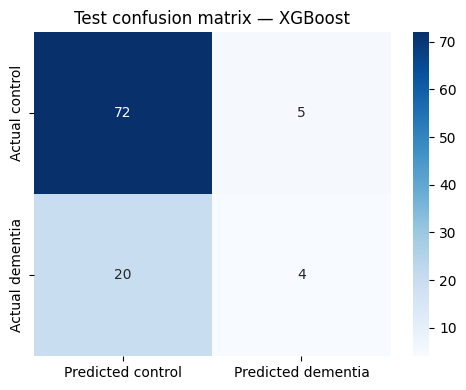

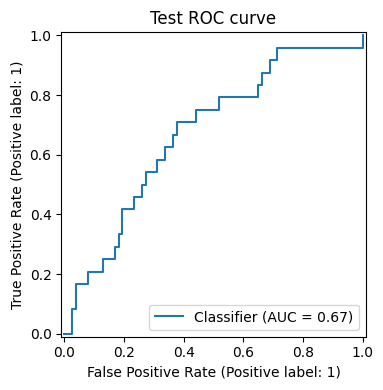

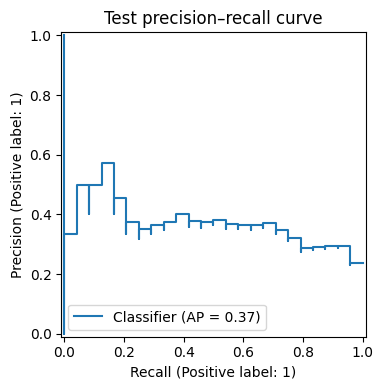

In [ ]:
best_name = val_results.iloc[0]['model']
best_model = fitted_models[best_name]
print('Selected using validation only:', best_name)

if hasattr(best_model, 'predict_proba'):
    test_prob = best_model.predict_proba(X_test)[:, 1]
else:
    test_score = best_model.decision_function(X_test)
    test_prob = (test_score - test_score.min()) / (test_score.max() - test_score.min() + 1e-9)

test_metrics = evaluate_probabilities(y_test, test_prob, threshold=0.5)
print('\nHeld-out test metrics (threshold = 0.5):')
display(pd.DataFrame([test_metrics]).round(4))
test_pred = (test_prob >= 0.5).astype(int)
print(classification_report(y_test, test_pred, target_names=['No dementia / control','Dementia'], zero_division=0))

cm = confusion_matrix(y_test, test_pred, labels=[0,1])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted control','Predicted dementia'], yticklabels=['Actual control','Actual dementia'])
plt.title(f'Test confusion matrix — {best_name}')
plt.tight_layout(); plt.show()

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, ax = plt.subplots(figsize=(5,4))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax)
ax.set_title('Test ROC curve'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(5,4))
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax)
ax.set_title('Test precision–recall curve'); plt.tight_layout(); plt.show()

## 11. Explainability: what features influence the chosen model?

Permutation importance on the validation set estimates how much the validation score drops when one feature is shuffled. It describes model reliance, **not causal or medical importance**.

,feature,importance_mean,importance_std
50,feat_mfcc_delta_6_mean,0.01178,0.00967
40,feat_mfcc_delta_1_mean,0.01061,0.00694
7,feat_spectral_centroid_std,0.00682,0.00227
81,feat_chroma_8_std,0.00455,0.00909
41,feat_mfcc_delta_1_std,0.00455,0.00371
42,feat_mfcc_delta_2_mean,0.00379,0.00379
79,feat_chroma_7_std,0.00303,0.00503
30,feat_mfcc_9_mean,0.00152,0.00567
26,feat_mfcc_7_mean,0.00076,0.00227
73,feat_chroma_4_std,0.00076,0.00530


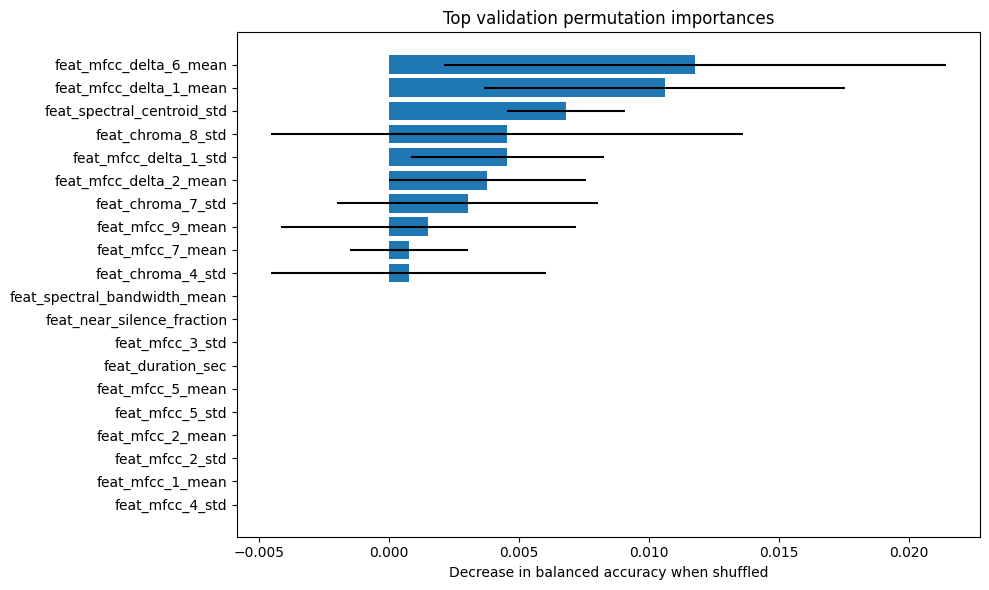

In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_val, y_val, n_repeats=10, random_state=SEED,
                              scoring='balanced_accuracy', n_jobs=-1)
importance = pd.DataFrame({'feature': feature_cols, 'importance_mean': perm.importances_mean,
                           'importance_std': perm.importances_std}).sort_values('importance_mean', ascending=False)
display(importance.head(20).round(5))
plt.figure(figsize=(10,6))
top_imp = importance.head(20).sort_values('importance_mean')
plt.barh(top_imp['feature'], top_imp['importance_mean'], xerr=top_imp['importance_std'])
plt.title('Top validation permutation importances')
plt.xlabel('Decrease in balanced accuracy when shuffled')
plt.tight_layout(); plt.show()

## 12. Optional deep-learning baseline: CNN over log-mel spectrograms

**Run this only after the classical ML pipeline works.** With a small number of independent people, a CNN may overfit and perform worse than classical ML. The code uses the same group-safe split. It compresses each clip's log-mel spectrogram to a fixed shape, trains a small CNN with early stopping, and reports a separate held-out test result. Do not pick a final model by the test score; use validation results to compare and select.

Creating log-mel spectrograms:   0%|          | 0/514 [00:00<?, ?it/s]

Saved new log-mel cache: (514, 64, 256, 1)
Training clips: 318
Training speakers: 132
Validation clips: 95
Validation speakers: 43
Speaker-level class counts: [85 47]
Class weights: {0: np.float64(0.7764705882352941), 1: np.float64(1.4042553191489362)}
Sample weights: (318,)
Epoch 1/60
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 295ms/step - accuracy: 0.4465 - auc: 0.5073 - loss: 0.7282 - val_accuracy: 0.6947 - val_auc: 0.4781 - val_loss: 0.6759 - val_speaker_loss: 0.6930 - val_speaker_balanced_accuracy: 0.5000 - val_speaker_auc: 0.5541 - learning_rate: 0.0010
Epoch 2/60
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 277ms/step - accuracy: 0.5000 - auc: 0.5487 - loss: 0.6895 - val_accuracy: 0.6947 - val_auc: 0.5502 - val_loss: 0.6784 - val_speaker_loss: 0.6927 - val_speaker_balanced_accuracy: 0.5000 - val_speaker_auc: 0.5281 - learning_rate: 0.0010
Epoch 3/60
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 314ms/step - accuracy: 0.4277 - auc: 0.5288 - loss: 0.7017 - val_accuracy: 0.3684 - val_auc: 0.5073 - val_loss: 0.6963 - val_spe

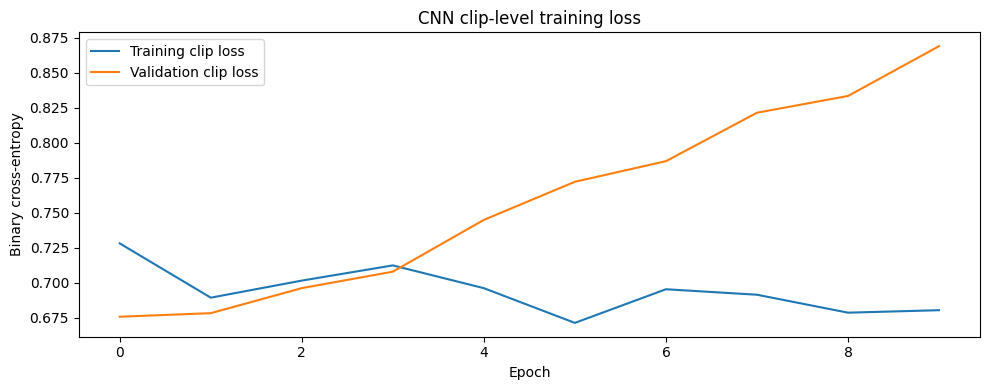

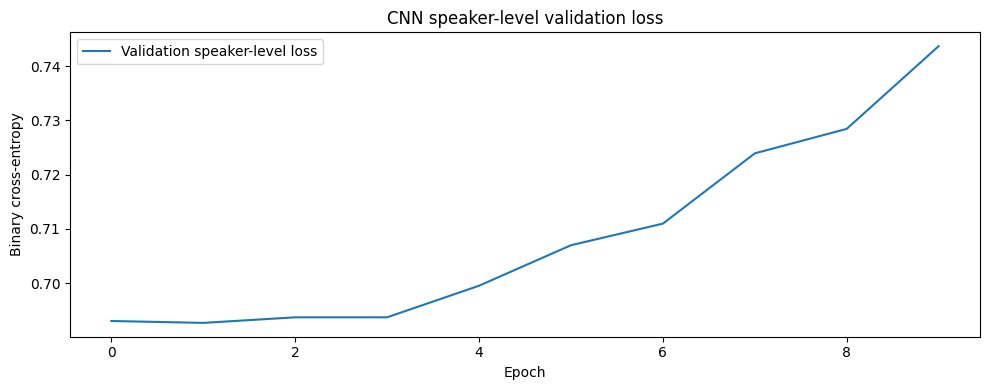


CNN speaker-level validation
Validation speakers: 43
ROC-AUC: 0.5281
Average precision: 0.5211

Top CNN thresholds by speaker-level validation balanced accuracy:


,threshold,balanced_accuracy,dementia_recall,specificity,precision,f1_dementia,TP,FN,TN,FP
0,0.48,0.555,0.429,0.682,0.562,0.486,9,12,15,7
1,0.05,0.500,1.000,0.000,0.488,0.656,21,0,0,22
2,0.06,0.500,1.000,0.000,0.488,0.656,21,0,0,22
3,0.07,0.500,1.000,0.000,0.488,0.656,21,0,0,22
4,0.08,0.500,1.000,0.000,0.488,0.656,21,0,0,22
5,0.09,0.500,1.000,0.000,0.488,0.656,21,0,0,22
6,0.10,0.500,1.000,0.000,0.488,0.656,21,0,0,22
7,0.11,0.500,1.000,0.000,0.488,0.656,21,0,0,22
8,0.12,0.500,1.000,0.000,0.488,0.656,21,0,0,22
9,0.13,0.500,1.000,0.000,0.488,0.656,21,0,0,22



Selected validation threshold: 0.48
Validation balanced accuracy: 0.5552
Validation dementia recall: 0.4286
Validation specificity: 0.6818

CNN model saved to: /content/drive/MyDrive/DementiaVoiceAI/outputs/logmel_cnn.keras
Validation results saved to: /content/drive/MyDrive/DementiaVoiceAI/outputs

Test data was not evaluated. Compare the CNN against the RBF SVM using validation results before deciding which model to evaluate on the held-out test set.


In [ ]:

# ============================================================
# SECTION 12 — CNN OVER LOG-MEL SPECTROGRAMS
# Speaker-weighted training + speaker-level validation
# Threshold selection uses validation only; no test evaluation.
# ============================================================

RUN_CNN = True

if RUN_CNN:
    import json
    import numpy as np
    import pandas as pd
    import tensorflow as tf
    import matplotlib.pyplot as plt

    from pathlib import Path
    from scipy.signal import resample
    from sklearn.metrics import (
        balanced_accuracy_score,
        roc_auc_score,
        average_precision_score,
        confusion_matrix,
        recall_score,
        precision_score,
        f1_score,
    )

    tf.keras.utils.set_random_seed(SEED)

    OUTPUT_DIR = Path(OUTPUT_DIR)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # 1. Validate the existing split and metadata
    # --------------------------------------------------------
    required_cols = {"audio_path", "label", "speaker_id"}
    missing_cols = required_cols - set(model_df.columns)

    if missing_cols:
        raise ValueError(
            f"model_df is missing required columns: {missing_cols}"
        )

    if model_df["speaker_id"].isna().any():
        raise ValueError("Missing speaker IDs. Fix them before CNN training.")

    model_labels = model_df["label"].astype(int).to_numpy()

    if not set(np.unique(model_labels)).issubset({0, 1}):
        raise ValueError("Labels must be binary: 0 = control, 1 = dementia.")

    train_idx = np.asarray(train_idx, dtype=int)
    val_idx = np.asarray(val_idx, dtype=int)
    test_idx = np.asarray(test_idx, dtype=int)

    # Check that partitions are valid and non-overlapping.
    if (
        len(np.unique(train_idx)) != len(train_idx)
        or len(np.unique(val_idx)) != len(val_idx)
        or len(np.unique(test_idx)) != len(test_idx)
    ):
        raise ValueError("Duplicate row indices found in a data partition.")

    if (
        set(train_idx) & set(val_idx)
        or set(train_idx) & set(test_idx)
        or set(val_idx) & set(test_idx)
    ):
        raise ValueError("Train, validation and test rows overlap.")

    if min(train_idx.min(), val_idx.min(), test_idx.min()) < 0:
        raise ValueError("Negative split indices found.")

    if max(train_idx.max(), val_idx.max(), test_idx.max()) >= len(model_df):
        raise ValueError("A split index is outside model_df.")

    # Ensure a speaker never crosses partitions.
    split_speakers = {
        "train": set(model_df.iloc[train_idx]["speaker_id"].astype(str)),
        "validation": set(model_df.iloc[val_idx]["speaker_id"].astype(str)),
        "test": set(model_df.iloc[test_idx]["speaker_id"].astype(str)),
    }

    assert not (split_speakers["train"] & split_speakers["validation"])
    assert not (split_speakers["train"] & split_speakers["test"])
    assert not (split_speakers["validation"] & split_speakers["test"])

    y_train = np.asarray(y_train).astype(int).ravel()
    y_val = np.asarray(y_val).astype(int).ravel()

    if not np.array_equal(y_train, model_labels[train_idx]):
        raise ValueError("y_train does not match model_df and train_idx.")

    if not np.array_equal(y_val, model_labels[val_idx]):
        raise ValueError("y_val does not match model_df and val_idx.")

    # This cell trains on train rows and monitors validation rows only.
    # test_idx and test labels are deliberately not used below.

    # --------------------------------------------------------
    # 2. Create fixed-size log-mel spectrograms
    # --------------------------------------------------------
    MEL_BINS = 64
    MEL_FRAMES = 256
    N_FFT = 400
    HOP_LENGTH = 320

    def logmel_image(path):
        yy, sr = librosa.load(
            str(path),
            sr=SR,
            mono=True,
            duration=MAX_AUDIO_SECONDS
        )

        if len(yy) == 0:
            raise ValueError(f"Empty audio file: {path}")

        mel = librosa.feature.melspectrogram(
            y=yy,
            sr=sr,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            n_mels=MEL_BINS,
            power=2.0
        )

        logmel = librosa.power_to_db(mel, ref=np.max)

        # Standardize each recording and resize its time axis.
        logmel = resample(
            logmel,
            MEL_FRAMES,
            axis=1
        )

        mu = np.mean(logmel)
        sigma = np.std(logmel)
        logmel = (logmel - mu) / (sigma + 1e-6)

        return logmel.astype("float32")[..., None]

    # Cache manifest prevents using a cache from another file order
    # or another spectrogram configuration.
    mel_cache = OUTPUT_DIR / "logmel_cache.npy"
    mel_manifest = OUTPUT_DIR / "logmel_cache_manifest.json"

    ordered_paths = model_df["audio_path"].astype(str).tolist()

    current_manifest = {
        "paths": ordered_paths,
        "sr": str(SR),
        "max_audio_seconds": str(MAX_AUDIO_SECONDS),
        "mel_bins": MEL_BINS,
        "mel_frames": MEL_FRAMES,
        "n_fft": N_FFT,
        "hop_length": HOP_LENGTH,
    }

    X_mel = None

    if mel_cache.exists() and mel_manifest.exists():
        try:
            with open(mel_manifest, "r", encoding="utf-8") as f:
                previous_manifest = json.load(f)

            cached = np.load(mel_cache, mmap_mode="r")

            if (
                previous_manifest == current_manifest
                and cached.shape == (
                    len(model_df), MEL_BINS, MEL_FRAMES, 1
                )
            ):
                X_mel = cached
                print("Using validated log-mel cache:", X_mel.shape)
            else:
                print("Cache manifest or shape changed; rebuilding cache.")

        except Exception as exc:
            print("Could not use existing cache:", repr(exc))

    if X_mel is None:
        tensors = []

        for path in tqdm(
            ordered_paths,
            desc="Creating log-mel spectrograms"
        ):
            tensors.append(logmel_image(path))

        X_mel = np.stack(tensors).astype("float32")

        np.save(mel_cache, X_mel)

        with open(mel_manifest, "w", encoding="utf-8") as f:
            json.dump(current_manifest, f)

        print("Saved new log-mel cache:", X_mel.shape)

    # --------------------------------------------------------
    # 3. Build the train and validation tensors
    # --------------------------------------------------------
    Xm_train = X_mel[train_idx]
    Xm_val = X_mel[val_idx]

    input_shape = Xm_train.shape[1:]

    train_meta = (
        model_df.iloc[train_idx]
        [["speaker_id", "label"]]
        .reset_index(drop=True)
        .copy()
    )

    val_meta = (
        model_df.iloc[val_idx]
        [["speaker_id", "label"]]
        .reset_index(drop=True)
        .copy()
    )

    train_meta["speaker_id"] = train_meta["speaker_id"].astype(str)
    val_meta["speaker_id"] = val_meta["speaker_id"].astype(str)

    # Each speaker must have one consistent binary label.
    if (
        train_meta.groupby("speaker_id")["label"].nunique().gt(1).any()
        or val_meta.groupby("speaker_id")["label"].nunique().gt(1).any()
    ):
        raise ValueError(
            "A speaker has conflicting labels. Investigate labels "
            "and speaker IDs before training."
        )

    if train_meta["label"].nunique() != 2:
        raise ValueError("Training split must contain both classes.")

    if val_meta["label"].nunique() != 2:
        raise ValueError("Validation split must contain both classes.")

    print("Training clips:", len(train_meta))
    print("Training speakers:", train_meta["speaker_id"].nunique())
    print("Validation clips:", len(val_meta))
    print("Validation speakers:", val_meta["speaker_id"].nunique())

    # --------------------------------------------------------
    # 4. Calculate speaker-balanced and class-balanced weights
    # --------------------------------------------------------
    # One speaker with many clips should not dominate training.
    clips_per_speaker = train_meta["speaker_id"].value_counts()

    weight_per_clip = (
        1.0 / train_meta["speaker_id"].map(clips_per_speaker)
    ).to_numpy(dtype="float32")

    # Balance classes based on the number of speakers, not clips.
    train_speaker_labels = (
        train_meta[["speaker_id", "label"]]
        .drop_duplicates("speaker_id")["label"]
        .astype(int)
        .to_numpy()
    )

    speaker_class_counts = np.bincount(
        train_speaker_labels,
        minlength=2
    )

    if np.any(speaker_class_counts == 0):
        raise ValueError(
            "Both classes need training speakers for class balancing."
        )

    total_speakers = len(train_speaker_labels)

    speaker_class_weights = {
        cls: total_speakers / (2.0 * speaker_class_counts[cls])
        for cls in [0, 1]
    }

    class_weight_per_clip = (
        train_meta["label"]
        .astype(int)
        .map(speaker_class_weights)
        .to_numpy(dtype="float32")
    )

    # Multiply inverse-speaker-size weights by class weights.
    # This preserves equal total weight per speaker within each class.
    sample_weights = weight_per_clip * class_weight_per_clip
    sample_weights /= sample_weights.mean()

    print("Speaker-level class counts:", speaker_class_counts)
    print("Class weights:", speaker_class_weights)
    print("Sample weights:", sample_weights.shape)

    # --------------------------------------------------------
    # 5. Build the CNN
    # --------------------------------------------------------
    cnn = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),

        tf.keras.layers.Conv2D(
            16, (3, 3), padding="same", activation="relu"
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.Conv2D(
            32, (3, 3), padding="same", activation="relu"
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.Conv2D(
            64, (3, 3), padding="same", activation="relu"
        ),
        tf.keras.layers.GlobalAveragePooling2D(),

        tf.keras.layers.Dropout(0.35),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dropout(0.25),

        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    cnn.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    # --------------------------------------------------------
    # 6. Speaker-level validation callback
    # --------------------------------------------------------
    class SpeakerValidationCallback(tf.keras.callbacks.Callback):
        """
        Aggregate validation clip probabilities by speaker each epoch.
        Adds speaker-level loss/AUC to callback logs.
        """

        def __init__(self, X_validation, metadata):
            super().__init__()
            self.X_validation = X_validation
            self.metadata = metadata[
                ["speaker_id", "label"]
            ].reset_index(drop=True).copy()
            self.epoch_metrics = []

        def on_epoch_end(self, epoch, logs=None):
            if logs is None:
                return

            clip_probs = self.model.predict(
                self.X_validation,
                verbose=0
            ).ravel()

            frame = self.metadata.copy()
            frame["probability"] = clip_probs

            grouped = (
                frame.groupby("speaker_id")
                .agg(
                    label=("label", "first"),
                    probability=("probability", "mean")
                )
                .reset_index()
            )

            y_speaker = grouped["label"].astype(int).to_numpy()
            p_speaker = np.clip(
                grouped["probability"].to_numpy(),
                1e-7,
                1.0 - 1e-7
            )

            # Binary cross-entropy over speaker-aggregated probabilities.
            speaker_loss = -np.mean(
                y_speaker * np.log(p_speaker)
                + (1 - y_speaker) * np.log(1 - p_speaker)
            )

            logs["val_speaker_loss"] = float(speaker_loss)

            speaker_pred = (p_speaker >= 0.5).astype(int)

            logs["val_speaker_balanced_accuracy"] = float(
                balanced_accuracy_score(y_speaker, speaker_pred)
            )

            if len(np.unique(y_speaker)) == 2:
                logs["val_speaker_auc"] = float(
                    roc_auc_score(y_speaker, p_speaker)
                )
            else:
                logs["val_speaker_auc"] = np.nan

            self.epoch_metrics.append({
                "epoch": epoch + 1,
                "val_speaker_loss": float(speaker_loss),
                "val_speaker_balanced_accuracy": logs[
                    "val_speaker_balanced_accuracy"
                ],
                "val_speaker_auc": logs["val_speaker_auc"]
            })

    speaker_val_callback = SpeakerValidationCallback(
        Xm_val, val_meta
    )

    callbacks = [
        # Must run before callbacks that monitor val_speaker_loss.
        speaker_val_callback,

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_speaker_loss",
            mode="min",
            patience=3,
            factor=0.5,
            min_lr=1e-6,
            verbose=1
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_speaker_loss",
            mode="min",
            patience=8,
            restore_best_weights=True,
            verbose=1
        )
    ]

    # --------------------------------------------------------
    # 7. Train with speaker/class weights
    # --------------------------------------------------------
    history = cnn.fit(
        Xm_train,
        y_train,
        sample_weight=sample_weights,
        validation_data=(Xm_val, y_val),
        epochs=60,
        batch_size=16,
        callbacks=callbacks,
        verbose=1
    )

    # --------------------------------------------------------
    # 8. Plot training history
    # --------------------------------------------------------
    history_df = pd.DataFrame(history.history)

    plt.figure(figsize=(10, 4))
    if "loss" in history_df:
        plt.plot(history_df["loss"], label="Training clip loss")
    if "val_loss" in history_df:
        plt.plot(history_df["val_loss"], label="Validation clip loss")
    plt.title("CNN clip-level training loss")
    plt.xlabel("Epoch")
    plt.ylabel("Binary cross-entropy")
    plt.legend()
    plt.tight_layout()
    plt.show()

    if "val_speaker_loss" in history_df:
        plt.figure(figsize=(10, 4))
        plt.plot(
            history_df["val_speaker_loss"],
            label="Validation speaker-level loss"
        )
        plt.title("CNN speaker-level validation loss")
        plt.xlabel("Epoch")
        plt.ylabel("Binary cross-entropy")
        plt.legend()
        plt.tight_layout()
        plt.show()

    if not history_df.empty:
        history_df.to_csv(
            OUTPUT_DIR / "cnn_training_history.csv",
            index=False
        )

    # --------------------------------------------------------
    # 9. Aggregate final validation predictions by speaker
    # --------------------------------------------------------
    cnn_val_clip_prob = cnn.predict(
        Xm_val,
        verbose=0
    ).ravel()

    val_predictions = val_meta.copy()
    val_predictions["probability"] = cnn_val_clip_prob

    cnn_val_speakers = (
        val_predictions.groupby("speaker_id")
        .agg(
            label=("label", "first"),
            probability=("probability", "mean")
        )
        .reset_index()
    )

    y_val_speaker = cnn_val_speakers["label"].astype(int).to_numpy()
    p_val_speaker = cnn_val_speakers["probability"].to_numpy()

    if len(np.unique(y_val_speaker)) != 2:
        raise ValueError(
            "Both classes are needed in speaker-level validation."
        )

    print("\nCNN speaker-level validation")
    print("Validation speakers:", len(cnn_val_speakers))
    print(
        "ROC-AUC:",
        round(roc_auc_score(y_val_speaker, p_val_speaker), 4)
    )
    print(
        "Average precision:",
        round(average_precision_score(y_val_speaker, p_val_speaker), 4)
    )

    # --------------------------------------------------------
    # 10. Select a threshold from validation only
    # --------------------------------------------------------
    threshold_rows = []

    for threshold in np.arange(0.05, 0.96, 0.01):
        pred = (p_val_speaker >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_speaker,
            pred,
            labels=[0, 1]
        ).ravel()

        threshold_rows.append({
            "threshold": round(float(threshold), 2),
            "balanced_accuracy": balanced_accuracy_score(
                y_val_speaker, pred
            ),
            "dementia_recall": recall_score(
                y_val_speaker, pred, zero_division=0
            ),
            "specificity": (
                tn / (tn + fp) if (tn + fp) else np.nan
            ),
            "precision": precision_score(
                y_val_speaker, pred, zero_division=0
            ),
            "f1_dementia": f1_score(
                y_val_speaker, pred, zero_division=0
            ),
            "TP": tp,
            "FN": fn,
            "TN": tn,
            "FP": fp
        })

    cnn_threshold_results = pd.DataFrame(threshold_rows).sort_values(
        ["balanced_accuracy", "dementia_recall"],
        ascending=False
    ).reset_index(drop=True)

    print("\nTop CNN thresholds by speaker-level validation balanced accuracy:")
    display(cnn_threshold_results.head(10).round(3))

    best_row = cnn_threshold_results.iloc[0]
    CNN_VALIDATION_THRESHOLD = float(best_row["threshold"])

    print(
        "\nSelected validation threshold:",
        CNN_VALIDATION_THRESHOLD
    )
    print(
        "Validation balanced accuracy:",
        round(float(best_row["balanced_accuracy"]), 4)
    )
    print(
        "Validation dementia recall:",
        round(float(best_row["dementia_recall"]), 4)
    )
    print(
        "Validation specificity:",
        round(float(best_row["specificity"]), 4)
    )

    # Save validation-only outputs and threshold for later comparison.
    cnn_val_speakers.to_csv(
        OUTPUT_DIR / "cnn_speaker_validation_predictions.csv",
        index=False
    )

    cnn_threshold_results.to_csv(
        OUTPUT_DIR / "cnn_validation_thresholds.csv",
        index=False
    )

    with open(
        OUTPUT_DIR / "cnn_validation_threshold.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump({
            "model": "CNN_logmel",
            "selected_threshold": CNN_VALIDATION_THRESHOLD,
            "selection_metric": "speaker-level validation balanced accuracy",
            "test_evaluated": False
        }, f, indent=2)

    cnn.save(OUTPUT_DIR / "logmel_cnn.keras")

    print("\nCNN model saved to:", OUTPUT_DIR / "logmel_cnn.keras")
    print("Validation results saved to:", OUTPUT_DIR)
    print(
        "\nTest data was not evaluated. Compare the CNN against the "
        "RBF SVM using validation results before deciding which model "
        "to evaluate on the held-out test set."
    )

else:
    print("RUN_CNN=False. CNN training skipped.")


## 13. Save model, feature schema, metrics, and reproducibility information

The saved ML model expects the exact feature columns in `feature_columns.json`. This artifact predicts from **engineered feature rows**, not raw audio; the same extraction function must be run for an input file before inference.

In [ ]:
import joblib, sklearn, librosa

model_path = OUTPUT_DIR / 'best_audio_feature_model.joblib'
joblib.dump(best_model, model_path)
with open(OUTPUT_DIR / 'feature_columns.json', 'w') as f:
    json.dump(feature_cols, f, indent=2)
with open(OUTPUT_DIR / 'run_config.json', 'w') as f:
    json.dump({
        'selected_model': best_name,
        'positive_class': 1,
        'negative_class': 0,
        'positive_label_name': 'dementia',
        'negative_label_name': 'no dementia / control',
        'sample_rate': SR,
        'max_audio_seconds': MAX_AUDIO_SECONDS,
        'speaker_group_column_or_method': str(SPEAKER_COL or 'filename-derived; verify manually'),
        'seed': SEED,
        'feature_columns': feature_cols,
        'sklearn_version': sklearn.__version__,
        'librosa_version': librosa.__version__,
    }, f, indent=2)
val_results.to_csv(OUTPUT_DIR / 'validation_model_comparison.csv', index=False)
pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / 'heldout_test_metrics.csv', index=False)
importance.to_csv(OUTPUT_DIR / 'permutation_importance.csv', index=False)
print('Saved artifacts:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, '-', f'{p.stat().st_size/1024:.1f} KB' if p.is_file() else 'directory')

Saved artifacts:
audio_features.csv - 990.5 KB
best_audio_feature_model.joblib - 339.0 KB
feature_columns.json - 2.2 KB
heldout_test_metrics.csv - 0.3 KB
permutation_importance.csv - 3.9 KB
run_config.json - 2.8 KB
validation_model_comparison.csv - 1.0 KB


## 14. Example inference on a new WAV/MP3 file

This runs the exact feature extractor, orders values using the saved feature schema, and applies the selected model. The probability is a model score—not the probability that a person medically has Alzheimer's disease. It should not be used for diagnosis.

In [ ]:
def predict_audio_file(audio_path, trained_model=best_model, required_features=feature_cols, threshold=0.5):
    audio_path = str(Path(audio_path).resolve())
    f = {f'feat_{k}': v for k, v in extract_features(audio_path).items()}
    row = pd.DataFrame([f]).reindex(columns=required_features)
    prob = float(trained_model.predict_proba(row)[:, 1][0])
    pred = int(prob >= threshold)
    return {
        'file': Path(audio_path).name,
        'model_score_dementia_class': round(prob, 4),
        'threshold': threshold,
        'predicted_class': 'Dementia-like class (research output)' if pred == 1 else 'No-dementia/control-like class (research output)',
        'warning': 'Experimental research output only; not a diagnosis.'
    }

# Example: replace with an actual path to a new audio file.
# result = predict_audio_file('/content/drive/MyDrive/DementiaVoiceAI/new_audio.wav')
# print(json.dumps(result, indent=2))
print('Inference function is ready. Set an audio file path in the example above to use it.')

Inference function is ready. Set an audio file path in the example above to use it.


## 15. Final research checklist

Before writing your report or calling a model “best,” verify the following:

- [ ] Labels and positive/negative mapping were checked against the original metadata.
- [ ] Every speaker/person appears in only one of train, validation, and test.
- [ ] Filename-derived speaker IDs were manually validated or replaced with true participant IDs.
- [ ] The number of unique people—not just clips—is reported for each split.
- [ ] Data leakage from source, era, age, clip length, and recording channel was considered.
- [ ] Metrics include dementia sensitivity/recall, specificity, balanced accuracy, ROC-AUC, PR-AUC, and confusion matrix.
- [ ] A simple baseline was compared against more complex models.
- [ ] The final test set was not used for selecting or tuning the model.
- [ ] Performance uncertainty was acknowledged; with few subjects, use grouped cross-validation / repeated group splits for stronger evidence.
- [ ] Claims are limited to research screening experiments, not clinical diagnosis.

**Recommended order:** establish a trustworthy speaker-level split → finish EDA → classical feature-based ML → interpret errors → grouped cross-validation and confidence intervals → optional CNN / pretrained speech embeddings only if sample size and compute justify them.

## Troubleshooting: automated download or class validation failed

The metadata CSVs do not contain the audio waveforms. The download cell uses the exact Google Drive folder links documented in the [DementiaNet README](https://github.com/shreyasgite/dementianet) and prints an attempt result for each class. The audio scan uses only `data/audio_verified/dementia/` and `data/audio_verified/nodementia/`.

If the validation cell stops, inspect `DOWNLOAD SUMMARY` and the per-class file counts. A missing class means Google Drive access/download did not succeed or that folder is empty/unreadable. The notebook intentionally stops rather than inventing labels or reporting misleading metrics. Once both class directories contain audio, rerun the verification cell and continue from metadata inspection.

Top 20 features by validation permutation importance:


,feature,importance_mean,importance_std
0,feat_mfcc_delta_4_std,0.0129,0.0117
1,feat_mfcc_4_std,0.0119,0.0119
2,feat_mfcc_delta_4_mean,0.0066,0.0181
3,feat_mfcc_delta_12_mean,0.0032,0.0169
4,feat_mfcc_4_mean,0.0011,0.0050
5,feat_chroma_11_mean,0.0011,0.0050
6,feat_chroma_1_mean,0.0011,0.0050
7,feat_near_silence_fraction,0.0011,0.0050
8,feat_chroma_10_mean,0.0011,0.0050
9,feat_zero_crossing_rate_std,0.0011,0.0050


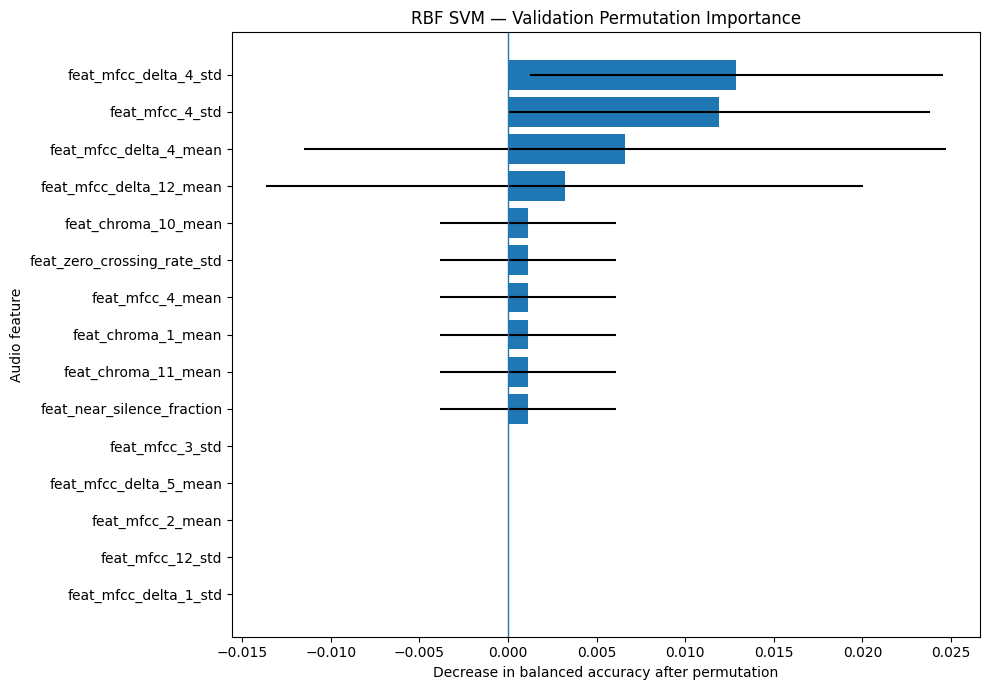


Interpretation: larger positive values suggest the feature helps validation predictions. Near-zero or negative values do not show useful standalone importance in this analysis.


In [ ]:

# ============================================================
# FEATURE IMPORTANCE — RBF SVM
# Permutation importance using validation speakers.
# Exploratory interpretation, not feature selection.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# selected_model remains the RBF SVM from the speaker-level experiment.
# X_val_sp and y_val_sp contain speaker-level validation data.

perm_result = permutation_importance(
    selected_model,
    X_val_sp,
    y_val_sp,
    scoring="balanced_accuracy",
    n_repeats=20,
    random_state=SEED,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": speaker_feature_cols,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

print("Top 20 features by validation permutation importance:")
display(importance_df.head(20).round(4))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values(
    "importance_mean"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["feature"],
    top_features["importance_mean"],
    xerr=top_features["importance_std"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Decrease in balanced accuracy after permutation")
plt.ylabel("Audio feature")
plt.title("RBF SVM — Validation Permutation Importance")
plt.tight_layout()
plt.show()

print(
    "\nInterpretation: larger positive values suggest the feature "
    "helps validation predictions. Near-zero or negative values "
    "do not show useful standalone importance in this analysis."
)


In [ ]:

# ============================================================
# FEATURE-GROUP ABLATION — RBF SVM
# 5-fold CV on training speakers only.
# Validation/test data are not used for feature selection.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

# Speaker-level training table: one row per inferred speaker
train_data = train_sp.copy()

feature_cols = [
    c for c in speaker_feature_cols
    if c in train_data.columns
    and pd.api.types.is_numeric_dtype(train_data[c])
]

# Define feature groups automatically from column names.
feature_groups = {
    "All features": feature_cols,

    "All MFCC": [
        c for c in feature_cols
        if "mfcc" in c.lower()
    ],

    "Static MFCC": [
        c for c in feature_cols
        if "mfcc" in c.lower()
        and "delta" not in c.lower()
    ],

    "MFCC delta": [
        c for c in feature_cols
        if "mfcc" in c.lower()
        and "delta" in c.lower()
    ],

    "Chroma": [
        c for c in feature_cols
        if "chroma" in c.lower()
    ],

    "Non-MFCC": [
        c for c in feature_cols
        if "mfcc" not in c.lower()
    ],

    "Non-MFCC, non-chroma": [
        c for c in feature_cols
        if "mfcc" not in c.lower()
        and "chroma" not in c.lower()
    ],
}

# Remove duplicate feature sets and groups with too few columns.
valid_groups = {}
seen_sets = set()

for name, cols in feature_groups.items():
    cols = list(dict.fromkeys(cols))
    signature = tuple(cols)

    if len(cols) < 2 or signature in seen_sets:
        continue

    valid_groups[name] = cols
    seen_sets.add(signature)

print("Training speakers:", len(train_data))
print("Number of candidate feature groups:", len(valid_groups))

y = train_data["label"].astype(int).to_numpy()

if len(np.unique(y)) != 2:
    raise ValueError("The training speakers must contain both classes.")

# Each row represents one speaker, so use stratified folds.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Use the original RBF SVM estimator as a template.
svm_template = models["RBF SVM"]

results = []

for group_name, cols in valid_groups.items():
    print(f"Evaluating {group_name}: {len(cols)} features")

    X_group = (
        train_data[cols]
        .replace([np.inf, -np.inf], np.nan)
    )

    scores = cross_validate(
        clone(svm_template),
        X_group,
        y,
        cv=cv,
        scoring={
            "balanced_accuracy": "balanced_accuracy",
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
        },
        n_jobs=-1,
        error_score="raise",
    )

    results.append({
        "feature_group": group_name,
        "n_features": len(cols),
        "balanced_accuracy_mean":
            scores["test_balanced_accuracy"].mean(),
        "balanced_accuracy_std":
            scores["test_balanced_accuracy"].std(ddof=1),
        "roc_auc_mean":
            scores["test_roc_auc"].mean(),
        "roc_auc_std":
            scores["test_roc_auc"].std(ddof=1),
        "average_precision_mean":
            scores["test_average_precision"].mean(),
    })

ablation_results = (
    pd.DataFrame(results)
    .sort_values("balanced_accuracy_mean", ascending=False)
    .reset_index(drop=True)
)

print("\nFeature-group comparison — training-only CV:")
display(ablation_results.round(3))

print(
    "\nUse these results to identify promising feature groups. "
    "Small differences relative to fold variability may not be meaningful. "
    "Do not evaluate the test set during this experiment."
)


Training speakers: 132
Number of candidate feature groups: 7
Evaluating All features: 90 features
Evaluating All MFCC: 52 features
Evaluating Static MFCC: 26 features
Evaluating MFCC delta: 26 features
Evaluating Chroma: 24 features
Evaluating Non-MFCC: 38 features
Evaluating Non-MFCC, non-chroma: 14 features

Feature-group comparison — training-only CV:


,feature_group,n_features,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,average_precision_mean
0,All features,90,0.712,0.056,0.738,0.028,0.622
1,Static MFCC,26,0.703,0.100,0.750,0.041,0.665
2,All MFCC,52,0.690,0.102,0.708,0.078,0.598
3,Non-MFCC,38,0.634,0.035,0.661,0.081,0.553
4,"Non-MFCC, non-chroma",14,0.628,0.069,0.641,0.029,0.554
5,MFCC delta,26,0.597,0.098,0.637,0.088,0.505
6,Chroma,24,0.557,0.108,0.544,0.109,0.511



Use these results to identify promising feature groups. Small differences relative to fold variability may not be meaningful. Do not evaluate the test set during this experiment.


In [ ]:

# ============================================================
# EXPERIMENT: ALL FEATURES vs STATIC MFCC
# RBF SVM | Speaker-level data
# Feature/model selection uses validation data only.
# Test data remains untouched.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# Feature definitions from the existing feature table
all_features = [
    c for c in speaker_feature_cols
    if c in train_sp.columns and c in val_sp.columns
]

static_mfcc_features = [
    c for c in all_features
    if "mfcc" in c.lower()
    and "delta" not in c.lower()
]

feature_sets = {
    "All features": all_features,
    "Static MFCC": static_mfcc_features,
}

if len(all_features) == 0 or len(static_mfcc_features) == 0:
    raise ValueError("Required feature groups were not found.")

ytr = train_sp["label"].astype(int).to_numpy()
yva = val_sp["label"].astype(int).to_numpy()

if len(np.unique(ytr)) != 2 or len(np.unique(yva)) != 2:
    raise ValueError(
        "Both classes must be present in training and validation."
    )

comparison_rows = []
fitted_candidates = {}

for group_name, features in feature_sets.items():
    print(f"\nTraining {group_name}: {len(features)} features")

    Xtr = (
        train_sp[features]
        .replace([np.inf, -np.inf], np.nan)
    )
    Xva = (
        val_sp[features]
        .replace([np.inf, -np.inf], np.nan)
    )

    # Clone the previously defined RBF SVM pipeline.
    estimator = clone(models["RBF SVM"])
    estimator.fit(Xtr, ytr)

    # Validation probabilities only
    probabilities = estimator.predict_proba(Xva)[:,
        list(estimator.classes_).index(1)
    ]

    fitted_candidates[group_name] = {
        "model": estimator,
        "features": features,
        "probabilities": probabilities,
    }

    # Metrics at the conventional 0.50 threshold
    pred_05 = (probabilities >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        yva, pred_05, labels=[0, 1]
    ).ravel()

    # Explore thresholds on validation only
    threshold_candidates = []

    for threshold in np.arange(0.05, 0.96, 0.01):
        prediction = (probabilities >= threshold).astype(int)

        tn_t, fp_t, fn_t, tp_t = confusion_matrix(
            yva, prediction, labels=[0, 1]
        ).ravel()

        threshold_candidates.append({
            "threshold": float(threshold),
            "balanced_accuracy": balanced_accuracy_score(
                yva, prediction
            ),
            "dementia_recall": recall_score(
                yva, prediction, zero_division=0
            ),
            "specificity": (
                tn_t / (tn_t + fp_t)
                if tn_t + fp_t else 0
            ),
            "precision": precision_score(
                yva, prediction, zero_division=0
            ),
            "f1_dementia": f1_score(
                yva, prediction, zero_division=0
            ),
        })

    threshold_df = pd.DataFrame(threshold_candidates)

    # Break ties by choosing the threshold closest to 0.50.
    threshold_df["distance_from_05"] = (
        threshold_df["threshold"] - 0.50
    ).abs()

    best = threshold_df.sort_values(
        ["balanced_accuracy", "distance_from_05"],
        ascending=[False, True]
    ).iloc[0]

    comparison_rows.append({
        "feature_group": group_name,
        "n_features": len(features),
        "val_balanced_accuracy_05":
            balanced_accuracy_score(yva, pred_05),
        "val_recall_05":
            recall_score(yva, pred_05, zero_division=0),
        "val_specificity_05":
            tn / (tn + fp) if tn + fp else 0,
        "val_roc_auc":
            roc_auc_score(yva, probabilities),
        "val_average_precision":
            average_precision_score(yva, probabilities),
        "best_val_threshold": best["threshold"],
        "best_val_balanced_accuracy": best["balanced_accuracy"],
        "best_val_dementia_recall": best["dementia_recall"],
        "best_val_specificity": best["specificity"],
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\nValidation comparison:")
display(
    comparison_df.sort_values(
        "val_roc_auc", ascending=False
    ).round(3)
)

print(
    "\nDo not select a feature set using test results. "
    "Review validation discrimination and the recall-specificity "
    "trade-off before locking the experiment."
)



Training All features: 90 features

Training Static MFCC: 26 features

Validation comparison:


,feature_group,n_features,val_balanced_accuracy_05,val_recall_05,val_specificity_05,val_roc_auc,val_average_precision,best_val_threshold,best_val_balanced_accuracy,best_val_dementia_recall,best_val_specificity
1,Static MFCC,26,0.596,0.238,0.955,0.753,0.747,0.31,0.745,0.762,0.727
0,All features,90,0.645,0.381,0.909,0.686,0.718,0.45,0.693,0.476,0.909



Do not select a feature set using test results. Review validation discrimination and the recall-specificity trade-off before locking the experiment.


In [ ]:

# ============================================================
# FINAL COMPARISON: STATIC MFCC + RBF SVM
# Uses threshold selected from validation data only.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Lock the configuration selected using validation results.
FINAL_FEATURE_GROUP = "Static MFCC"
FINAL_THRESHOLD = 0.31

candidate = fitted_candidates[FINAL_FEATURE_GROUP]
final_model = candidate["model"]
final_features = candidate["features"]

# Test data is used only for final evaluation.
X_test_final = (
    test_sp[final_features]
    .replace([np.inf, -np.inf], np.nan)
)

y_test_final = test_sp["label"].astype(int).to_numpy()

if len(np.unique(y_test_final)) != 2:
    raise ValueError("Test set must contain both classes.")

# Predict probabilities for dementia class 1.
positive_index = list(final_model.classes_).index(1)

test_prob_final = final_model.predict_proba(
    X_test_final
)[:, positive_index]

test_pred_final = (
    test_prob_final >= FINAL_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test_final,
    test_pred_final,
    labels=[0, 1]
).ravel()

final_metrics = {
    "model": "RBF SVM — Static MFCC",
    "features": len(final_features),
    "threshold": FINAL_THRESHOLD,
    "accuracy": accuracy_score(
        y_test_final, test_pred_final
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test_final, test_pred_final
    ),
    "roc_auc": roc_auc_score(
        y_test_final, test_prob_final
    ),
    "average_precision": average_precision_score(
        y_test_final, test_prob_final
    ),
    "dementia_precision": precision_score(
        y_test_final, test_pred_final,
        zero_division=0
    ),
    "dementia_recall": recall_score(
        y_test_final, test_pred_final,
        zero_division=0
    ),
    "specificity": (
        tn / (tn + fp) if (tn + fp) else np.nan
    ),
    "dementia_f1": f1_score(
        y_test_final, test_pred_final,
        zero_division=0
    ),
}

print("Selected model:", FINAL_FEATURE_GROUP)
print("Number of features:", len(final_features))
print("Threshold selected on validation:", FINAL_THRESHOLD)

print("\nHeld-out test results:")
display(pd.DataFrame([final_metrics]).round(3))

print("\nConfusion matrix:")
print("                 Predicted control  Predicted dementia")
print(f"Actual control       {tn:>5}              {fp:>5}")
print(f"Actual dementia      {fn:>5}              {tp:>5}")

print("\nClassification report:")
print(classification_report(
    y_test_final,
    test_pred_final,
    labels=[0, 1],
    target_names=["Control", "Dementia"],
    zero_division=0
))

# Save the locked evaluation results.
results_path = OUTPUT_DIR / "static_mfcc_svm_test_results.csv"
pd.DataFrame([final_metrics]).to_csv(results_path, index=False)

print("\nTest results saved to:", results_path)


Selected model: Static MFCC
Number of features: 26
Threshold selected on validation: 0.31

Held-out test results:


,model,features,threshold,accuracy,balanced_accuracy,roc_auc,average_precision,dementia_precision,dementia_recall,specificity,dementia_f1
0,RBF SVM — Static MFCC,26,0.31,0.614,0.616,0.654,0.538,0.476,0.625,0.607,0.541



Confusion matrix:
                 Predicted control  Predicted dementia
Actual control          17                 11
Actual dementia          6                 10

Classification report:
              precision    recall  f1-score   support

     Control       0.74      0.61      0.67        28
    Dementia       0.48      0.62      0.54        16

    accuracy                           0.61        44
   macro avg       0.61      0.62      0.60        44
weighted avg       0.64      0.61      0.62        44


Test results saved to: /content/drive/MyDrive/DementiaVoiceAI/outputs/static_mfcc_svm_test_results.csv


In [ ]:

# ============================================================
# ERROR ANALYSIS — STATIC MFCC RBF SVM
# Descriptive analysis of existing test predictions.
# Do not use these errors to retune the model.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path

error_df = test_sp[
    ["speaker_id", "label"]
].copy().reset_index(drop=True)

error_df["probability_dementia"] = test_prob_final
error_df["predicted_label"] = test_pred_final

error_df["actual_class"] = error_df["label"].map({
    0: "Control",
    1: "Dementia"
})

error_df["predicted_class"] = error_df["predicted_label"].map({
    0: "Control",
    1: "Dementia"
})

error_df["error_type"] = np.select(
    [
        (error_df["label"] == 0) &
        (error_df["predicted_label"] == 1),

        (error_df["label"] == 1) &
        (error_df["predicted_label"] == 0),
    ],
    [
        "False positive",
        "False negative",
    ],
    default="Correct"
)

print("Test error summary:")
display(
    error_df["error_type"]
    .value_counts()
    .to_frame("speaker_count")
)

print("\nFalse negatives — missed dementia-labelled speakers:")
display(
    error_df[
        error_df["error_type"] == "False negative"
    ].sort_values(
        "probability_dementia",
        ascending=False
    )
)

print("\nFalse positives — controls predicted as dementia:")
display(
    error_df[
        error_df["error_type"] == "False positive"
    ].sort_values(
        "probability_dementia",
        ascending=False
    )
)

# Save this descriptive report for documentation.
output_path = Path(OUTPUT_DIR) / "static_mfcc_test_error_analysis.csv"
error_df.to_csv(output_path, index=False)

print("\nError analysis saved to:", output_path)


Test error summary:


,speaker_count
error_type,
Correct,27
False positive,11
False negative,6



False negatives — missed dementia-labelled speakers:


,speaker_id,label,probability_dementia,predicted_label,actual_class,predicted_class,error_type
3,antonyflew,1,0.286298,0,Dementia,Control,False negative
36,ronano_rahilly,1,0.271719,0,Dementia,Control,False negative
1,alanramsey,1,0.250245,0,Dementia,Control,False negative
38,sparkyanderson,1,0.209584,0,Dementia,Control,False negative
4,benbradlee,1,0.182665,0,Dementia,Control,False negative
9,davidmilch,1,0.143586,0,Dementia,Control,False negative



False positives — controls predicted as dementia:


,speaker_id,label,probability_dementia,predicted_label,actual_class,predicted_class,error_type
8,davidallancoe,0,0.810257,1,Control,Dementia,False positive
32,queen_elisabeth,0,0.639847,1,Control,Dementia,False positive
43,warren_buffett,0,0.574970,1,Control,Dementia,False positive
17,janefonda,0,0.530075,1,Control,Dementia,False positive
31,pele,0,0.505704,1,Control,Dementia,False positive
5,briandepalma,0,0.428089,1,Control,Dementia,False positive
25,judi_dench,0,0.382600,1,Control,Dementia,False positive
39,terrygilliam,0,0.375415,1,Control,Dementia,False positive
2,angelobadalamenti,0,0.371893,1,Control,Dementia,False positive
33,ralphlauren,0,0.337513,1,Control,Dementia,False positive



Error analysis saved to: /content/drive/MyDrive/DementiaVoiceAI/outputs/static_mfcc_test_error_analysis.csv


In [ ]:

# ============================================================
# SAVE FINAL STATIC MFCC SVM EXPERIMENT
# Does not retrain or retune the model.
# ============================================================

import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Package model, ordered feature names and fixed threshold.
model_artifact = {
    "model": final_model,
    "feature_names": list(final_features),
    "threshold": float(FINAL_THRESHOLD),
    "class_mapping": {
        "0": "No dementia / control",
        "1": "Dementia"
    },
    "model_type": "RBF SVM",
    "feature_group": "Static MFCC",
    "n_features": len(final_features),
    "warning": (
        "Experimental research model. Not validated for clinical diagnosis."
    )
}

model_path = OUTPUT_DIR / "dementiavoiceai_static_mfcc_svm.joblib"
joblib.dump(model_artifact, model_path)

# 2. Save the final metrics in JSON format.
metrics_json = {}

for key, value in final_metrics.items():
    if isinstance(value, (np.integer,)):
        value = int(value)
    elif isinstance(value, (np.floating,)):
        value = float(value)

    metrics_json[key] = value

metrics_json["split_unit"] = "inferred speaker"
metrics_json["threshold_source"] = "validation set"
metrics_json["feature_group"] = "Static MFCC"
metrics_json["clinical_validation"] = False

metrics_path = OUTPUT_DIR / "final_experiment_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_json, f, indent=2)

# 3. Save per-speaker test predictions for documentation.
prediction_report = test_sp[
    ["speaker_id", "label"]
].copy().reset_index(drop=True)

prediction_report["probability_dementia"] = test_prob_final
prediction_report["predicted_label"] = test_pred_final

prediction_report["error_type"] = np.select(
    [
        (prediction_report["label"] == 0) &
        (prediction_report["predicted_label"] == 1),

        (prediction_report["label"] == 1) &
        (prediction_report["predicted_label"] == 0)
    ],
    ["False positive", "False negative"],
    default="Correct"
)

prediction_path = OUTPUT_DIR / "final_test_predictions.csv"
prediction_report.to_csv(prediction_path, index=False)

print("Model saved:", model_path)
print("Metrics saved:", metrics_path)
print("Test prediction report saved:", prediction_path)
print("\nFeature count:", len(final_features))
print("Threshold:", FINAL_THRESHOLD)
print("All artifacts saved successfully.")


Model saved: /content/drive/MyDrive/DementiaVoiceAI/outputs/dementiavoiceai_static_mfcc_svm.joblib
Metrics saved: /content/drive/MyDrive/DementiaVoiceAI/outputs/final_experiment_metrics.json
Test prediction report saved: /content/drive/MyDrive/DementiaVoiceAI/outputs/final_test_predictions.csv

Feature count: 26
Threshold: 0.31
All artifacts saved successfully.


In [ ]:
import joblib

joblib.dump(
    {
        "model": final_model,
        "features": final_features,
        "threshold": FINAL_THRESHOLD
    },
    f"{OUTPUT_DIR}/dementiavoiceai_static_mfcc_svm.joblib"
)

['/content/drive/MyDrive/DementiaVoiceAI/outputs/dementiavoiceai_static_mfcc_svm.joblib']

In [ ]:
artifact = joblib.load(
    f"{OUTPUT_DIR}/dementiavoiceai_static_mfcc_svm.joblib"
)

model = artifact["model"]
features = artifact["features"]
threshold = artifact["threshold"]
